In [1]:
import sys
print(sys.executable)  # путь к Python
print(sys.version)  

/app/.venv/bin/python
3.14.7 (main, Sep 19 2026, 01:01:59) [GCC 14.2.0]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from scipy.stats import zscore
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import roc_auc_score

from tqdm.auto import tqdm
import optuna

/app/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import tqdm as notebook_tqdm

In [4]:
import subprocess

subprocess.run(["apt-get", "update", "-qq"], check=True)
subprocess.run(["apt-get", "install", "-y", "-qq", "libgomp1"], check=True)

from lightgbm import LGBMClassifier

In [5]:
import lazypredict

In [6]:
pd.set_option('display.max_columns',  10000)
pd.set_option('display.max_info_columns', 10000)

Посмотреть столбцы в таблицах в файле Data в директории

In [7]:
import pandas as pd
from pathlib import Path

data_dir = Path("data")
if not data_dir.is_dir():
    data_dir = Path.cwd().parent / "data"

if not data_dir.is_dir():
    raise FileNotFoundError(f"Папка data не найдена. Текущая директория: {Path.cwd()}")

for file_path in data_dir.glob("*.csv"):
    df = pd.read_csv(file_path)
    print(f"\n--- {file_path.name} ---")
    print(df.shape)
    print(df.columns.tolist())


--- bureau.csv ---
(24689, 8)
['client_id', 'bureau_account_id', 'account_type', 'opened_days_ago', 'credit_limit', 'current_balance', 'max_dpd_last_12m', 'bureau_status']

--- previous_loans.csv ---
(12762, 7)
['client_id', 'previous_loan_id', 'previous_amount', 'previous_term_months', 'closed_days_ago', 'was_overdue', 'max_overdue_days']

--- test.csv ---
(2520, 24)
['application_id', 'client_id', 'region_coefficient_extended', 'loan_term_months', 'siberia_northern_score', 'hash_id', 'loan_amount', 'post_loan_collection_score', 'months_at_job', 'channel', 'education', 'internal_decision_code', 'monthly_income', 'region', 'employment_type', 'days_until_first_overdue', 'incoming_amount', 'age', 'dependents', 'interest_rate', 'marketing_segment', 'region_coefficient', 'requested_product', 'application_date']

--- train.csv ---
(6488, 25)
['application_id', 'client_id', 'employment_type', 'hash_id', 'region_coefficient_extended', 'age', 'incoming_amount', 'internal_decision_code', 'mont

In [8]:
import os

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

db_name = os.environ["POSTGRES_DB"]
db_user = os.environ["POSTGRES_USER"]
db_password = os.environ["POSTGRES_PASSWORD"]
db_host = os.environ["POSTGRES_HOST"]
db_port = os.environ["POSTGRES_PORT"]

connection_url = (
    f"postgresql+psycopg2://{db_user}:{db_password}"
    f"@{db_host}:{db_port}/{db_name}"
)

engine = create_engine(connection_url)



Добавить табоицы в PostgreSQL

In [9]:
# CSV читается через read_csv, а не read_sql
# df = pd.read_csv("data/train.csv")
# df.to_sql("train", engine, if_exists="replace", index=False)

In [10]:
# CSV читается через read_csv, а не read_sql
# df = pd.read_csv("data/previous_loans.csv")
# df.to_sql("previous_loans", engine, if_exists="replace", index=False)

In [11]:
# CSV читается через read_csv, а не read_sql
# df = pd.read_csv("data/test.csv")
# df.to_sql("test", engine, if_exists="replace", index=False)

In [12]:
# CSV читается через read_csv, а не read_sql
# df = pd.read_csv("data/transactions.csv")
# df.to_sql("transactions", engine, if_exists="replace", index=False)

Загрузить сведения из PostgreSQL на сервере в notebook 

# EDA исходных датасетов

## Previous_loans


In [13]:
df_previous_loans = pd.read_sql(
    "SELECT * FROM previous_loans_clean",
    engine
)

df_previous_loans.head()

,client_id,previous_loan_id,previous_amount,previous_term_months,closed_days_ago,was_overdue,max_overdue_days
0,2,L2_0,51911.71,3.0,986.0,1.0,3.0
1,2,L2_1,64582.12,24.0,1172.0,0.0,0.0
2,3,L3_2,27102.97,3.0,744.0,0.0,0.0
3,4,L4_3,56399.68,12.0,139.0,1.0,15.0
4,4,L4_4,73117.38,18.0,548.0,0.0,0.0


In [14]:
df_previous_loans.drop_duplicates()
df_previous_loans.shape

(12762, 7)

In [15]:
df_previous_loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 12762 entries, 0 to 12761
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   client_id             12762 non-null  int64  
 1   previous_loan_id      12762 non-null  str    
 2   previous_amount       12445 non-null  float64
 3   previous_term_months  12117 non-null  float64
 4   closed_days_ago       12246 non-null  float64
 5   was_overdue           12496 non-null  float64
 6   max_overdue_days      12318 non-null  float64
dtypes: float64(5), int64(1), str(1)
memory usage: 698.1 KB


In [16]:
round(df_previous_loans.isnull().sum()/len(df_previous_loans)*100, 2)

client_id               0.00
previous_loan_id        0.00
previous_amount         2.48
previous_term_months    5.05
closed_days_ago         4.04
was_overdue             2.08
max_overdue_days        3.48
dtype: float64

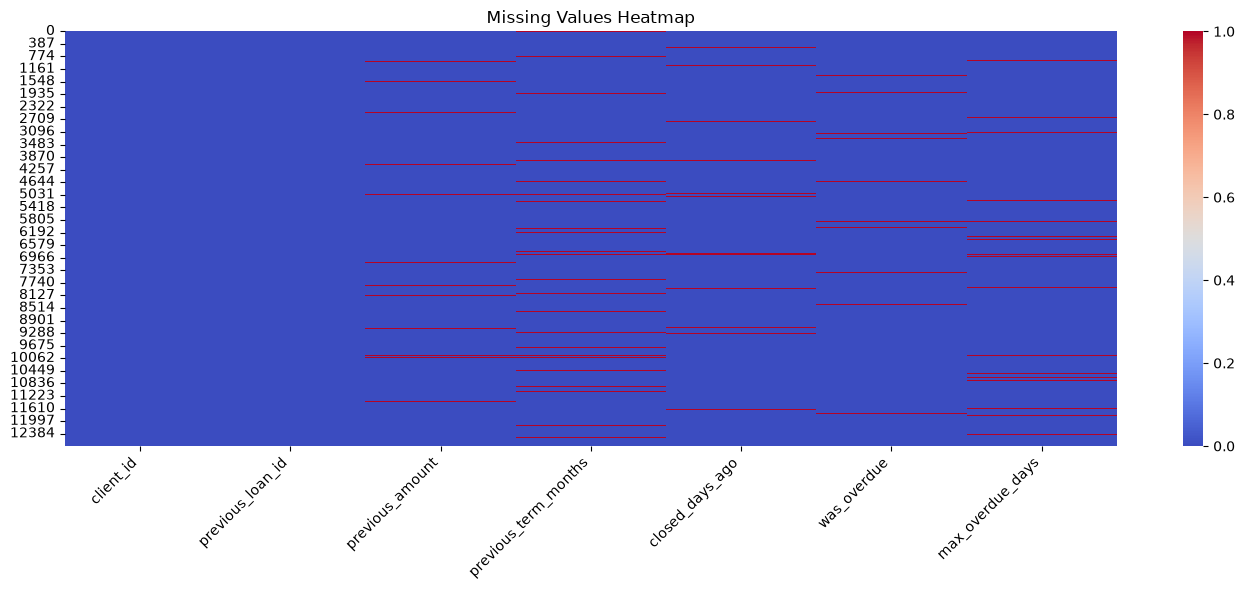

In [17]:
plt.figure(figsize=(14, 6))

sns.heatmap(df_previous_loans.isnull(), cmap='coolwarm')

plt.xticks(rotation=45, ha='right')
plt.title('Missing Values Heatmap')

plt.tight_layout()
plt.show()

### Handle missing values

### Удалим NAN в столбцах was_overdue и max_overdue_days, если в обоих на 1 строке был пропуск

In [18]:
df_previous_loans = df_previous_loans.dropna(subset=["was_overdue", "max_overdue_days"],how="all")
df_previous_loans.reset_index(drop=True, inplace=True)

### Если пропуск только у одного столбца

In [19]:
# Если просрочки не было, а дни просрочки неизвестны ставим 0
df_previous_loans.loc[(df_previous_loans["was_overdue"] == 0) & (df_previous_loans["max_overdue_days"].isna()),"max_overdue_days"] = 0

# Если просрочка была, но количество дней неизвестно удаляем строку
df_previous_loans = df_previous_loans.drop(df_previous_loans[(df_previous_loans["was_overdue"] == 1) & (df_previous_loans["max_overdue_days"].isna())].index)

# Если дней просрочки 0, а факт просрочки неизвестен ставим 0
df_previous_loans.loc[(df_previous_loans["max_overdue_days"] == 0) & (df_previous_loans["was_overdue"].isna()),"was_overdue"] = 0

# Если дней просрочки больше 0, а факт просрочки неизвестен ставим 1
df_previous_loans.loc[(df_previous_loans["max_overdue_days"] > 0) & (df_previous_loans["was_overdue"].isna()),"was_overdue"] = 1

### Заполнение пропусков numerical columns

In [20]:
cols = ["previous_amount", "previous_term_months", "closed_days_ago"]
for col in cols:
  # Заполнение с median группируя по client_id
  df_previous_loans[col] = df_previous_loans.groupby("client_id")[col].transform(lambda x: x.fillna(x.median()))
  # Заполнение оставшихся NaN общими median для всего столбца
  df_previous_loans[col] = df_previous_loans[col].fillna(df_previous_loans[col].median())
df_previous_loans.reset_index(drop=True, inplace=True)

По моему мнению такое заполнение максимально сохранит приближенность к реальным значениям

In [21]:
df_previous_loans.info()

<class 'pandas.DataFrame'>
RangeIndex: 12675 entries, 0 to 12674
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   client_id             12675 non-null  int64  
 1   previous_loan_id      12675 non-null  str    
 2   previous_amount       12675 non-null  float64
 3   previous_term_months  12675 non-null  float64
 4   closed_days_ago       12675 non-null  float64
 5   was_overdue           12675 non-null  float64
 6   max_overdue_days      12675 non-null  float64
dtypes: float64(5), int64(1), str(1)
memory usage: 693.3 KB


### Определим выбросы

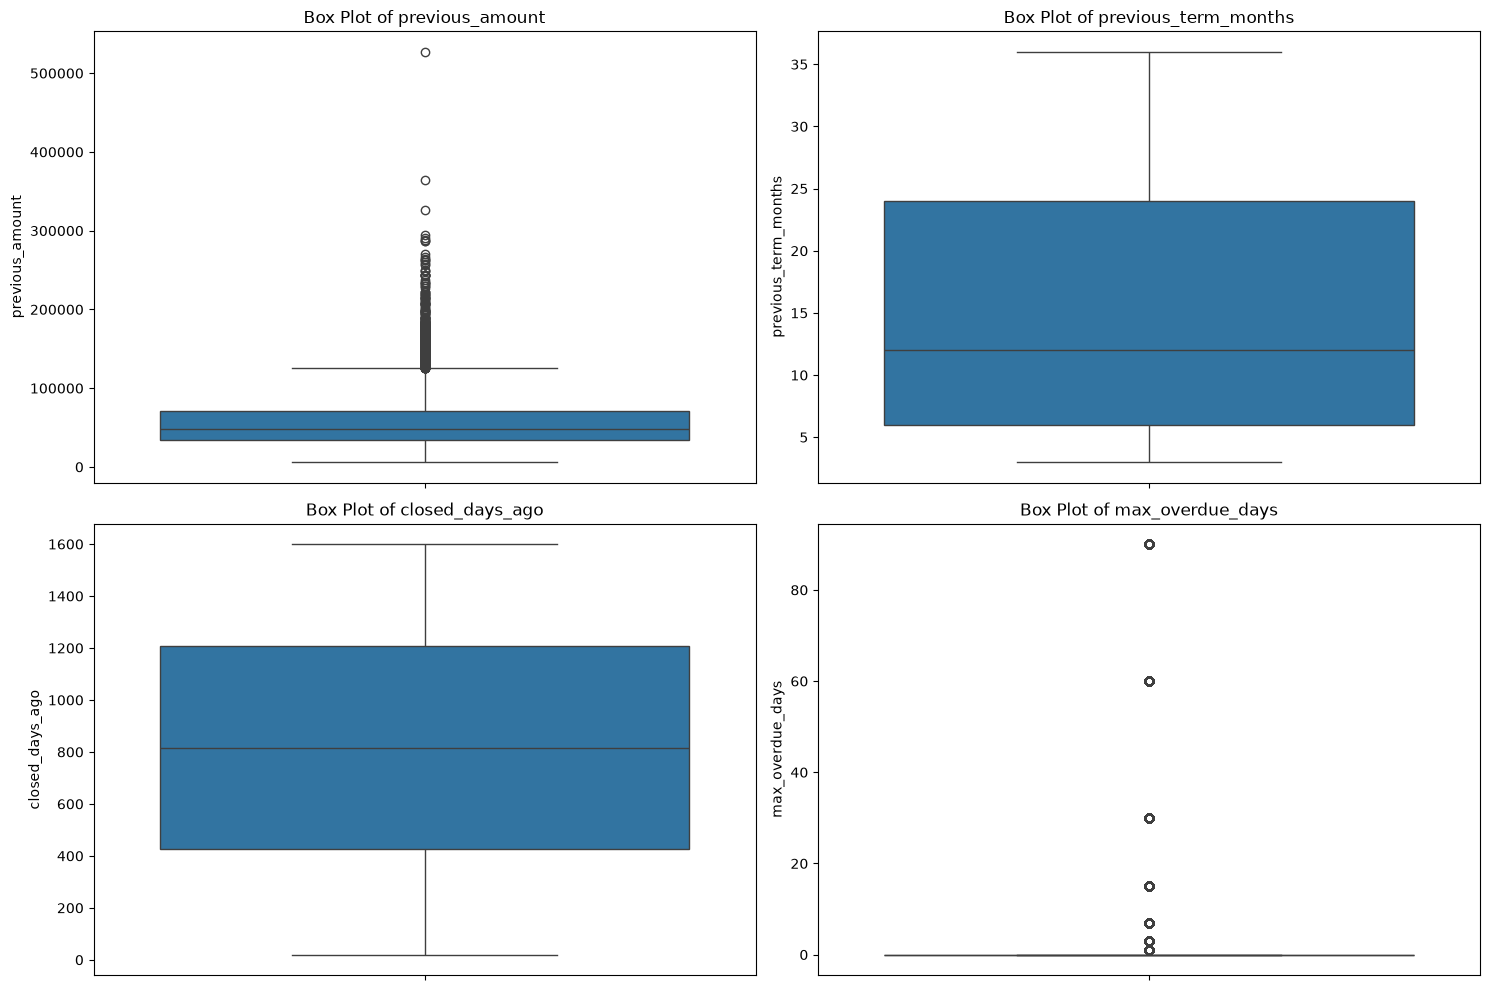

In [22]:
numerical_cols_previous_loans = [
    'previous_amount',
    'previous_term_months',
    'closed_days_ago',
    'max_overdue_days'
]

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols_previous_loans):
    plt.subplot(2, 2, i + 1) # Adjust grid size as needed
    sns.boxplot(y=df_previous_loans[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

### Correlation matrix

<Axes: >

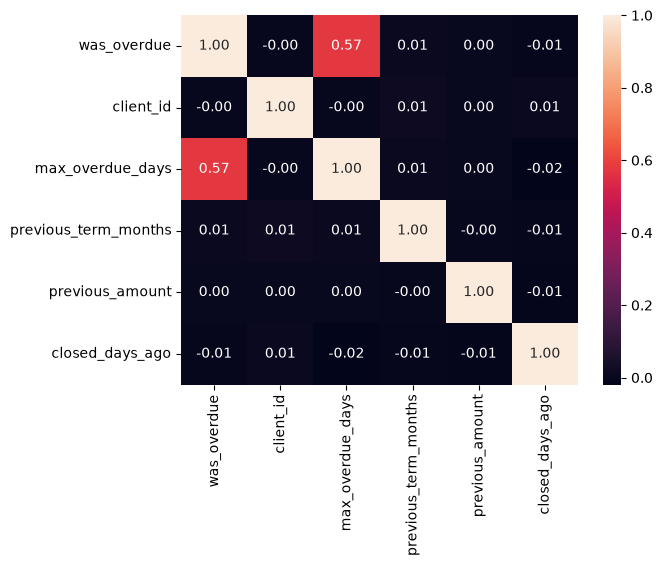

In [23]:
numerical_previous_loans = list(set(df_previous_loans.columns) - set(
        [
            "previous_loan_id"
        ]
    )
)
corr_matrix_previous_loans = df_previous_loans[numerical_previous_loans].corr()
sns.heatmap(corr_matrix_previous_loans, annot=True,
    fmt=".2f")

 ### Агрегируем previous_loans перед добавлением в Train Test

In [24]:
df_previous_loans = df_previous_loans.drop(columns='previous_loan_id')

In [25]:
df_previous_num = df_previous_loans.groupby('client_id').agg(
    previous_loans_count=('client_id', 'size'),  # Количество предыдущих займов
    previous_amount_sum=('previous_amount', 'sum'),   # Общая сумма предыдущих займов
    previous_amount_mean=('previous_amount', 'mean'),  # Средняя сумма предыдущего займа
    previous_term_mean=('previous_term_months', 'mean'),  # Средний срок предыдущих займов
    previous_oldest_closed=('closed_days_ago', 'max'),  # Самый давно закрытый займ
    previous_latest_closed=('closed_days_ago', 'min'),  # Самый недавно закрытый займ
    previous_max_overdue=('max_overdue_days', 'max'),  # Максимальная просрочка
    previous_mean_overdue=('max_overdue_days', 'mean')  # Средняя просрочка
).reset_index()
df_previous_num

,client_id,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue
0,2,2,116493.83,58246.915000,13.5,1172.0,986.0,3.0,1.5
1,3,1,27102.97,27102.970000,3.0,744.0,744.0,0.0,0.0
2,4,2,129517.06,64758.530000,15.0,548.0,139.0,15.0,7.5
3,5,2,150729.28,75364.640000,18.0,1314.0,1120.0,30.0,15.5
4,6,1,76959.39,76959.390000,36.0,151.0,151.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
6857,8995,1,29933.92,29933.920000,6.0,837.0,837.0,0.0,0.0
6858,8996,1,47405.09,47405.090000,12.0,111.0,111.0,90.0,90.0
6859,8997,3,172019.14,57339.713333,12.0,1581.0,270.0,0.0,0.0
6860,8999,2,105249.06,52624.530000,9.0,1251.0,573.0,0.0,0.0


In [26]:
previous_overdue = df_previous_loans.groupby('client_id').agg(
    previous_overdue_count=('was_overdue', 'sum'),
    previous_has_overdue=('was_overdue', 'max')).reset_index()
previous_overdue

,client_id,previous_overdue_count,previous_has_overdue
0,2,1.0,1.0
1,3,0.0,0.0
2,4,1.0,1.0
3,5,2.0,1.0
4,6,0.0,0.0
...,...,...,...
6857,8995,0.0,0.0
6858,8996,1.0,1.0
6859,8997,0.0,0.0
6860,8999,0.0,0.0


In [27]:
df_previous_features = (df_previous_num.merge(previous_overdue, on='client_id', how='left').fillna(0))
df_previous_features

,client_id,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue
0,2,2,116493.83,58246.915000,13.5,1172.0,986.0,3.0,1.5,1.0,1.0
1,3,1,27102.97,27102.970000,3.0,744.0,744.0,0.0,0.0,0.0,0.0
2,4,2,129517.06,64758.530000,15.0,548.0,139.0,15.0,7.5,1.0,1.0
3,5,2,150729.28,75364.640000,18.0,1314.0,1120.0,30.0,15.5,2.0,1.0
4,6,1,76959.39,76959.390000,36.0,151.0,151.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
6857,8995,1,29933.92,29933.920000,6.0,837.0,837.0,0.0,0.0,0.0,0.0
6858,8996,1,47405.09,47405.090000,12.0,111.0,111.0,90.0,90.0,1.0,1.0
6859,8997,3,172019.14,57339.713333,12.0,1581.0,270.0,0.0,0.0,0.0,0.0
6860,8999,2,105249.06,52624.530000,9.0,1251.0,573.0,0.0,0.0,0.0,0.0


## Bureau

In [28]:
df_bureau = pd.read_sql(
    "SELECT * FROM bureau_clean",
    engine
)

df_bureau.head()

,client_id,bureau_account_id,account_type,opened_days_ago,credit_limit,current_balance,max_dpd_last_12m,bureau_status
0,1,B1_0,credit_card,2410.0,20474.70,5760.10,0.0,active
1,2,B2_1,NaN,2983.0,61748.02,47175.10,1.0,active
2,3,B3_2,auto,943.0,93069.06,40725.25,15.0,active
3,3,B3_3,mortgage,2355.0,173852.51,57974.36,7.0,closed
4,3,B3_4,credit_card,302.0,24037.79,7801.91,1.0,closed


In [29]:
df_bureau.info()

<class 'pandas.DataFrame'>
RangeIndex: 24689 entries, 0 to 24688
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   client_id          24689 non-null  int64  
 1   bureau_account_id  24689 non-null  str    
 2   account_type       23852 non-null  str    
 3   opened_days_ago    24037 non-null  float64
 4   credit_limit       23862 non-null  float64
 5   current_balance    24209 non-null  float64
 6   max_dpd_last_12m   23832 non-null  float64
 7   bureau_status      23414 non-null  str    
dtypes: float64(4), int64(1), str(3)
memory usage: 1.5 MB


In [30]:
df_bureau = df_bureau.dropna(subset=["account_type", "max_dpd_last_12m","bureau_status"])
round(df_bureau.isnull().sum()/len(df_bureau)*100, 2)

client_id            0.00
bureau_account_id    0.00
account_type         0.00
opened_days_ago      2.62
credit_limit         3.40
current_balance      1.88
max_dpd_last_12m     0.00
bureau_status        0.00
dtype: float64

### Handle missing values

In [31]:
cols_bureau = ["opened_days_ago", "credit_limit", "current_balance"]
for col in cols_bureau:
  # Заполнение с median группируя по client_id
  df_bureau[col] = df_bureau.groupby("client_id")[col].transform(lambda x: x.fillna(x.median()))
  # Заполнение оставшихся NaN общими median для всего столбца
  df_bureau[col] = df_bureau[col].fillna(df_bureau[col].median())
df_bureau.reset_index(drop=True, inplace=True)

In [32]:
df_bureau.isna().sum()

client_id            0
bureau_account_id    0
account_type         0
opened_days_ago      0
credit_limit         0
current_balance      0
max_dpd_last_12m     0
bureau_status        0
dtype: int64

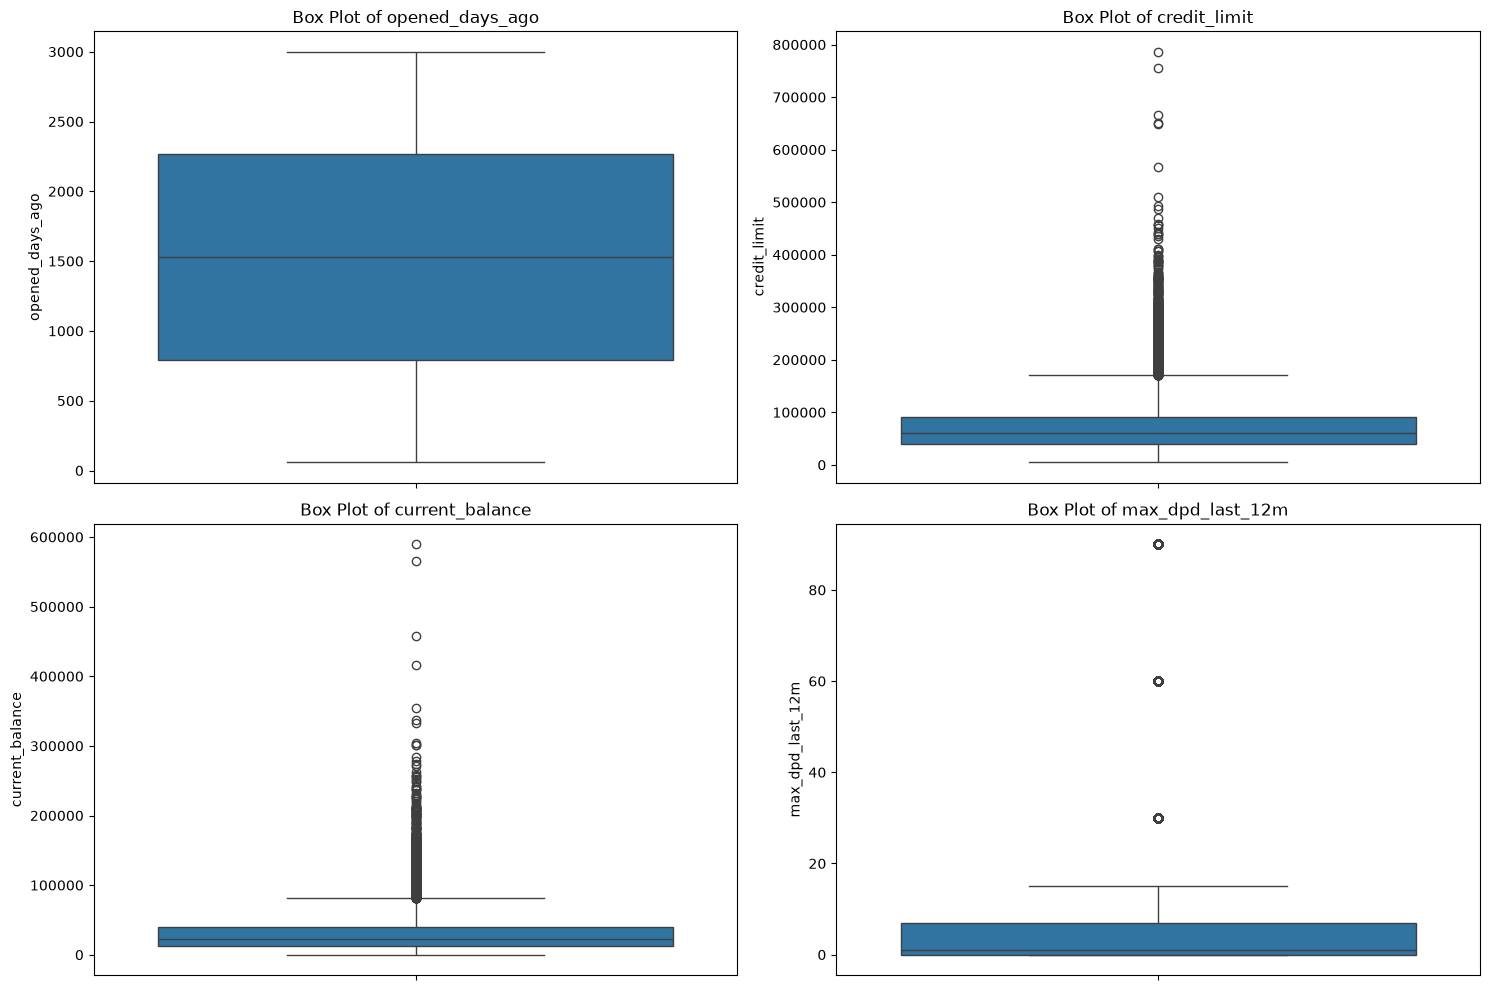

In [33]:
numerical_cols_bureau = [
     "opened_days_ago",
     "credit_limit",
     "current_balance",
     "max_dpd_last_12m"
]

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols_bureau):
    plt.subplot(2, 2, i + 1) # Adjust grid size as needed
    sns.boxplot(y=df_bureau[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

<Axes: xlabel='account_type', ylabel='count'>

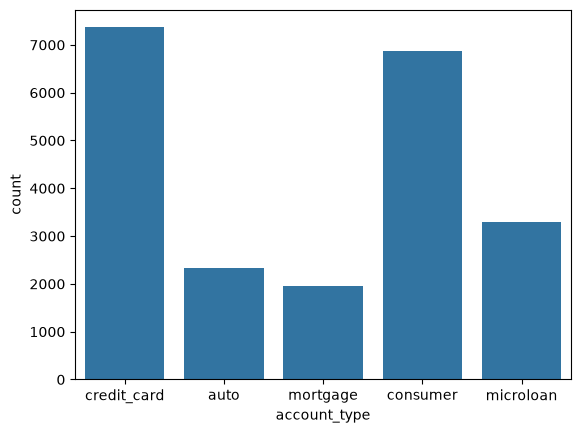

In [34]:
sns.countplot(x="account_type", data=df_bureau)

In [35]:
account_type = (pd.crosstab(df_bureau['client_id'],df_bureau['account_type']).add_prefix('account_type_').reset_index())
account_type

account_type,client_id,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage
0,1,0,0,1,0,0
1,3,1,1,1,0,1
2,4,0,3,1,0,0
3,5,0,1,0,1,0
4,6,0,0,1,0,0
...,...,...,...,...,...,...
8333,8996,0,0,2,0,0
8334,8997,0,1,1,0,0
8335,8998,0,0,1,0,0
8336,8999,1,1,0,0,0


<Axes: xlabel='bureau_status', ylabel='count'>

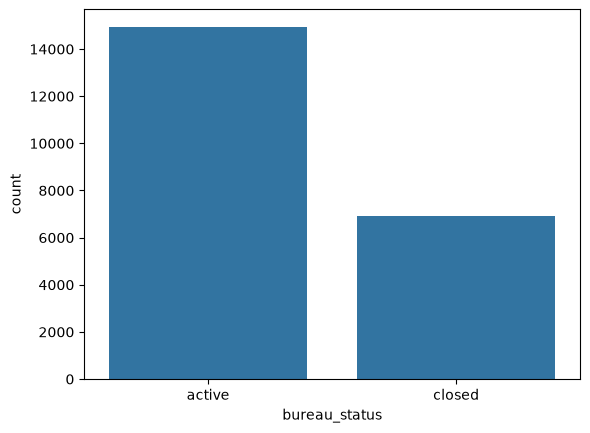

In [36]:
sns.countplot(x="bureau_status", data=df_bureau)

### Кодируем bureau_status с помощью Labelencoder

In [37]:
df_bureau['bureau_status']

0        active
1        active
2        closed
3        closed
4        closed
          ...  
21833    closed
21834    active
21835    closed
21836    closed
21837    active
Name: bureau_status, Length: 21838, dtype: str

In [38]:
labelencoder = LabelEncoder()

labelencoder = LabelEncoder()

df_bureau['bureau_status'] = labelencoder.fit_transform(
    df_bureau['bureau_status'].astype(str)
).astype(int)

df_bureau
df_bureau

,client_id,bureau_account_id,account_type,opened_days_ago,credit_limit,current_balance,max_dpd_last_12m,bureau_status
0,1,B1_0,credit_card,2410.0,20474.70,5760.10,0.0,0
1,3,B3_2,auto,943.0,93069.06,40725.25,15.0,0
2,3,B3_3,mortgage,2355.0,173852.51,57974.36,7.0,1
3,3,B3_4,credit_card,302.0,24037.79,7801.91,1.0,1
4,3,B3_5,consumer,2230.0,79926.76,45320.67,0.0,1
...,...,...,...,...,...,...,...,...
21833,3167,B3167_8582,consumer,364.0,91067.67,17600.82,0.0,1
21834,8918,B8918_24468,microloan,1637.0,21444.49,2981.00,1.0,0
21835,8681,B8681_23844,credit_card,2774.0,30805.62,17256.58,0.0,1
21836,7264,B7264_19920,microloan,380.0,69520.13,63747.35,3.0,1


### Correlation_matrix

<Axes: >

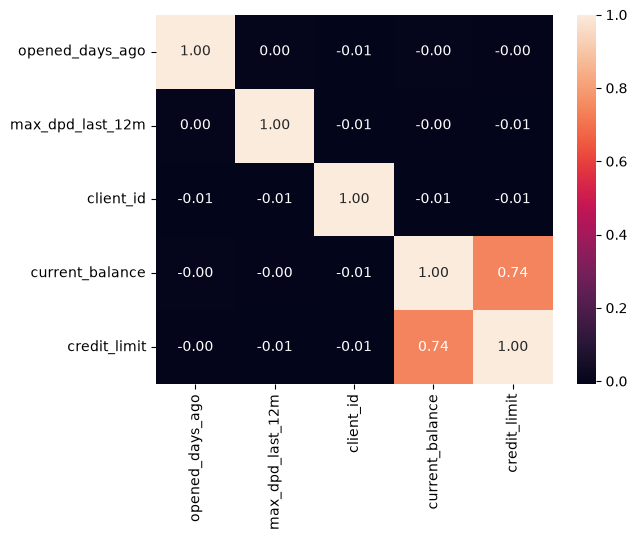

In [39]:
numerical_bureau = list(set(df_bureau.columns) - set(
        [
            "bureau_account_id",
            "account_type",
            "bureau_status"
        ]
    )
)
corr_matrix_bureau = df_bureau[numerical_bureau].corr()
sns.heatmap(corr_matrix_bureau, annot=True,
    fmt=".2f")

 ### Агрегируем BUREAU перед добавление в Train Test

In [40]:
df_bureau = df_bureau.drop(columns='bureau_account_id')

In [41]:
df_bureau_num = df_bureau.groupby('client_id').agg(
    bureau_accounts_count=('client_id', 'size'),  # Количество кредитных счетов
    bureau_total_balance=('current_balance', 'sum'),  # Общий текущий остаток по кредитам
    bureau_mean_balance=('current_balance', 'mean'),  # Средний текущий остаток по кредитам
    bureau_credit_limit_sum=('credit_limit', 'sum'),  # Общий кредитный лимит
    bureau_credit_limit_mean=('credit_limit', 'mean'),  # Средний кредитный лимит
    bureau_max_dpd=('max_dpd_last_12m', 'max'),  # Максимальная просрочка за последние 12 месяцев
    bureau_mean_dpd=('max_dpd_last_12m', 'mean'),  # Средняя просрочка за последние 12 месяцев
    bureau_oldest_credit=('opened_days_ago', 'max'),  # Самый старый открытый кредит
    bureau_newest_credit=('opened_days_ago', 'min')  # Самый новый открытый кредит
).reset_index()

df_bureau_num

,client_id,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit
0,1,1,5760.10,5760.1000,20474.70,20474.7000,0.0,0.00,2410.0,2410.0
1,3,4,151822.19,37955.5475,370886.12,92721.5300,15.0,5.75,2355.0,302.0
2,4,4,99113.84,24778.4600,333635.71,83408.9275,1.0,0.50,2688.0,972.0
3,5,2,71734.13,35867.0650,97896.18,48948.0900,1.0,0.50,2447.0,184.0
4,6,1,34572.29,34572.2900,50966.73,50966.7300,7.0,7.00,2933.0,2933.0
...,...,...,...,...,...,...,...,...,...,...
8333,8996,2,63534.64,31767.3200,150341.76,75170.8800,30.0,15.00,1893.0,278.0
8334,8997,2,288481.65,144240.8250,516615.66,258307.8300,0.0,0.00,642.0,552.0
8335,8998,1,11699.94,11699.9400,31561.47,31561.4700,0.0,0.00,2733.0,2733.0
8336,8999,2,99285.13,49642.5650,143015.66,71507.8300,7.0,3.50,2365.0,244.0


In [42]:
active = (df_bureau[df_bureau['bureau_status'] == 0].groupby('client_id').size().reset_index(name='bureau_active_accounts'))
closed = (df_bureau[df_bureau['bureau_status'] == 1].groupby('client_id').size().reset_index(name='bureau_closed_accounts'))

In [43]:
df_bureau_features = (df_bureau_num.merge(active, on='client_id', how='left').merge(closed, on='client_id', how='left').merge(account_type, on='client_id', how='left'))
df_bureau_features = df_bureau_features.fillna(0)
df_bureau_features

,client_id,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage
0,1,1,5760.10,5760.1000,20474.70,20474.7000,0.0,0.00,2410.0,2410.0,1.0,0.0,0,0,1,0,0
1,3,4,151822.19,37955.5475,370886.12,92721.5300,15.0,5.75,2355.0,302.0,1.0,3.0,1,1,1,0,1
2,4,4,99113.84,24778.4600,333635.71,83408.9275,1.0,0.50,2688.0,972.0,3.0,1.0,0,3,1,0,0
3,5,2,71734.13,35867.0650,97896.18,48948.0900,1.0,0.50,2447.0,184.0,1.0,1.0,0,1,0,1,0
4,6,1,34572.29,34572.2900,50966.73,50966.7300,7.0,7.00,2933.0,2933.0,1.0,0.0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8333,8996,2,63534.64,31767.3200,150341.76,75170.8800,30.0,15.00,1893.0,278.0,2.0,0.0,0,0,2,0,0
8334,8997,2,288481.65,144240.8250,516615.66,258307.8300,0.0,0.00,642.0,552.0,1.0,1.0,0,1,1,0,0
8335,8998,1,11699.94,11699.9400,31561.47,31561.4700,0.0,0.00,2733.0,2733.0,1.0,0.0,0,0,1,0,0
8336,8999,2,99285.13,49642.5650,143015.66,71507.8300,7.0,3.50,2365.0,244.0,1.0,1.0,1,1,0,0,0


## TRANSACTIONS

In [44]:
df_transactions = pd.read_sql(
    "SELECT * FROM transactions_clean",
    engine
)

df_transactions.head()

,client_id,application_id,transaction_date,transaction_category,amount,merchant_risk_level
0,1,100001,2025-10-22,transfer,-1538.95,5.0
1,1,100001,2025-07-10,cash_withdrawal,-1460.46,1.0
2,1,100001,2025-11-01,utilities,-988.50,2.0
3,1,100001,2025-10-10,salary,8578.27,3.0
4,1,100001,2025-12-24,entertainment,-2015.69,2.0


In [45]:
df_transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 353300 entries, 0 to 353299
Data columns (total 6 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   client_id             353300 non-null  int64  
 1   application_id        353300 non-null  int64  
 2   transaction_date      342664 non-null  str    
 3   transaction_category  335599 non-null  str    
 4   amount                341886 non-null  float64
 5   merchant_risk_level   338285 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 16.2 MB


### Handling missing values

### Удалим NaN из столбцов с object и заменим пропуски в numeric с заполнением гоуппируя по клиентам

In [46]:
df_transactions.dropna(subset = ["transaction_date", "transaction_category"], inplace=True)
df_transactions.reset_index(drop=True, inplace=True)
df_transactions. info()


<class 'pandas.DataFrame'>
RangeIndex: 325545 entries, 0 to 325544
Data columns (total 6 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   client_id             325545 non-null  int64  
 1   application_id        325545 non-null  int64  
 2   transaction_date      325545 non-null  str    
 3   transaction_category  325545 non-null  str    
 4   amount                315042 non-null  float64
 5   merchant_risk_level   311723 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 14.9 MB


In [47]:
df_transactions['transaction_category'].value_counts()

transaction_category
groceries          78027
transfer           48861
cash_withdrawal    48595
salary             38643
entertainment      33010
loan_payment       32718
utilities          32611
gambling           13080
Name: count, dtype: int64

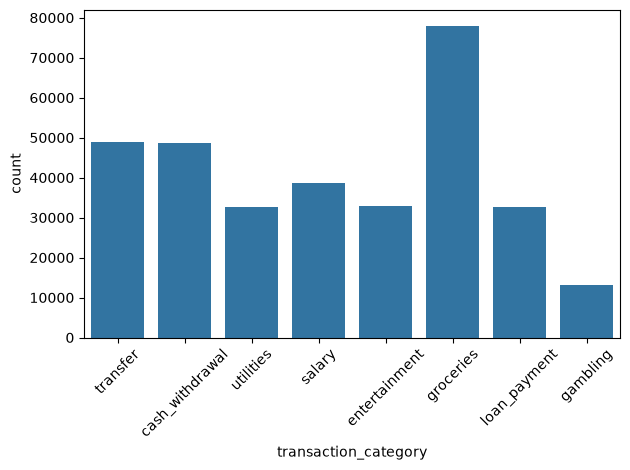

In [48]:
sns.countplot(x="transaction_category", data=df_transactions)
plt.xticks(rotation=45)
plt.tight_layout()

Numerical columns

In [49]:
cols_transaction = ["amount", "merchant_risk_level"]
for col in cols_transaction:
  df_transactions[col] = df_transactions.groupby("client_id")[col].transform(lambda x: x.fillna(x.median()))
df_transactions

,client_id,application_id,transaction_date,transaction_category,amount,merchant_risk_level
0,1,100001,2025-10-22,transfer,-1538.95,5.0
1,1,100001,2025-07-10,cash_withdrawal,-1460.46,1.0
2,1,100001,2025-11-01,utilities,-988.50,2.0
3,1,100001,2025-10-10,salary,8578.27,3.0
4,1,100001,2025-12-24,entertainment,-2015.69,2.0
...,...,...,...,...,...,...
325540,8386,108386,2025-03-20,groceries,-961.09,1.0
325541,727,100727,2025-08-12,groceries,-6750.90,1.0
325542,780,100780,2025-04-08,transfer,-1716.45,2.0
325543,7874,107874,2025-07-07,transfer,-3241.86,2.0


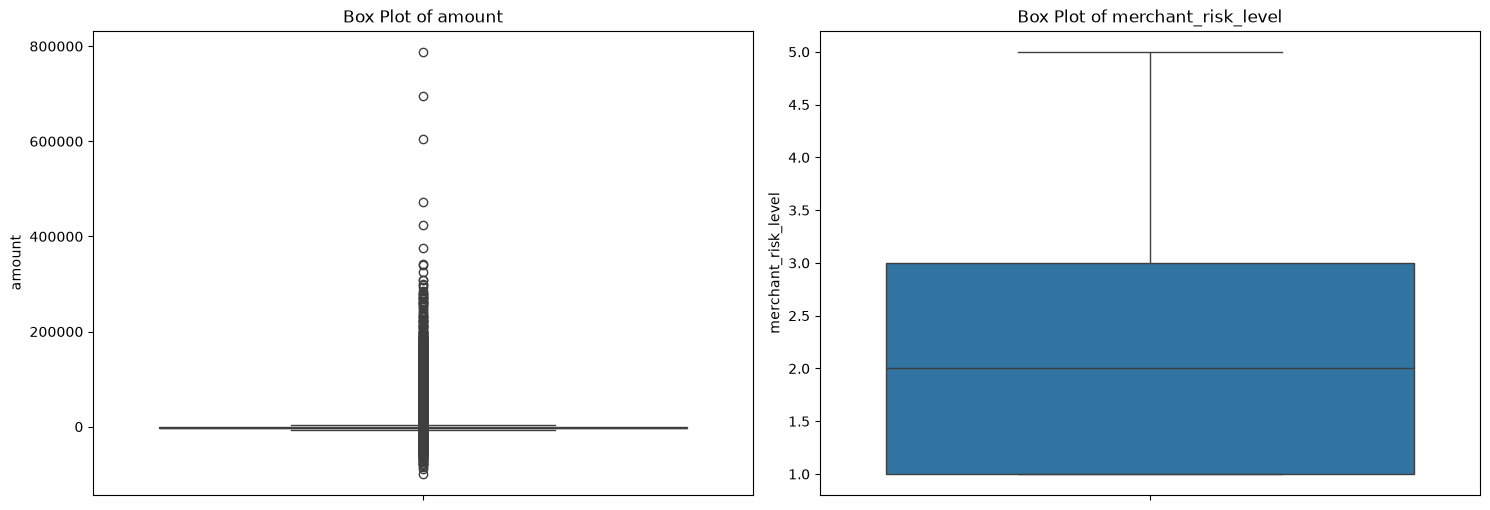

In [50]:
numerical_cols_transactions = [
    'amount',
    'merchant_risk_level'
]

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols_transactions):
    plt.subplot(2, 2, i + 1) # Adjust grid size as needed
    sns.boxplot(y=df_transactions[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

<Axes: >

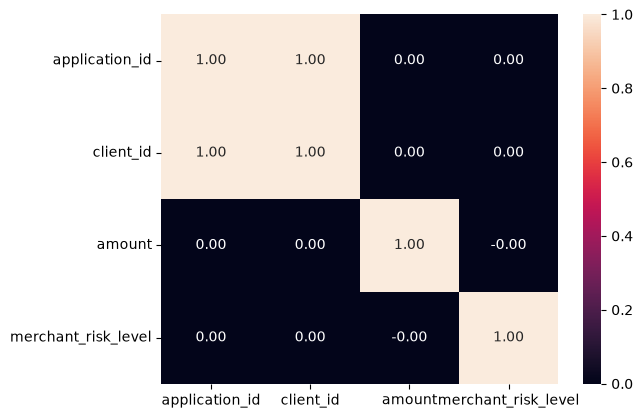

In [51]:
numerical_transactions = list(set(df_transactions.columns) - set(
        [
            "transaction_date",
            "transaction_category"
        ]
    )
)
corr_matrix_transactions = df_transactions[numerical_transactions].corr()
sns.heatmap(corr_matrix_transactions, annot=True,
    fmt=".2f")

 ### Агрегируем TRANSACTIONS перед добавление в Train Test

In [52]:
df_transactions = df_transactions.drop(columns='application_id')

In [53]:
df_transactions_num = df_transactions.groupby('client_id').agg(
    transactions_count=('amount', 'count'),  # Количество транзакций
    transaction_sum=('amount', 'sum'),  # Общая сумма транзакций
    transaction_mean=('amount', 'mean'),  # Средняя сумма транзакции
    transaction_max=('amount', 'max'),  # Максимальная сумма транзакции
    transaction_min=('amount', 'min'),  # Минимальная сумма транзакции
    merchant_risk_mean=('merchant_risk_level', 'mean'),  # Средний уровень риска продавцов
    merchant_risk_max=('merchant_risk_level', 'max')  # Максимальный уровень риска продавцов
).reset_index()
df_transactions_num

,client_id,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max
0,1,32,-29899.300,-934.353125,13713.54,-7458.31,2.156250,5.0
1,2,46,-114930.710,-2498.493696,35205.43,-26301.58,2.282609,5.0
2,3,36,-7825.850,-217.384722,28242.46,-8977.95,2.194444,5.0
3,4,42,15952.350,379.817857,52061.96,-16157.98,2.238095,5.0
4,5,29,18205.880,627.788966,38326.67,-5347.45,2.034483,5.0
...,...,...,...,...,...,...,...,...
8995,8996,27,47520.530,1760.019630,102812.87,-10004.00,1.925926,4.0
8996,8997,40,91841.440,2296.036000,81416.27,-19587.42,2.600000,5.0
8997,8998,31,2429.260,78.363226,38095.35,-9000.60,2.225806,5.0
8998,8999,37,-36532.805,-987.373108,39109.03,-11412.36,1.864865,5.0


In [54]:
income = (df_transactions[df_transactions['amount'] > 0].groupby('client_id')['amount'].sum().reset_index(name='income_sum'))
expense = (df_transactions[df_transactions['amount'] < 0].groupby('client_id')['amount'].sum().reset_index(name='expense_sum'))

In [55]:
transaction_categories = (pd.crosstab(df_transactions['client_id'],df_transactions['transaction_category'])
    .reset_index()
)

In [56]:
df_transactions_features = (
    df_transactions_num
    .merge(income, on='client_id', how='left')
    .merge(expense, on='client_id', how='left')
    .merge(transaction_categories, on='client_id', how='left')
    .fillna(0)
)
df_transactions_features

,client_id,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities
0,1,32,-29899.300,-934.353125,13713.54,-7458.31,2.156250,5.0,45115.59,-75014.890,6,2,1,6,5,4,3,5
1,2,46,-114930.710,-2498.493696,35205.43,-26301.58,2.282609,5.0,53651.69,-168582.400,8,1,2,11,2,2,13,7
2,3,36,-7825.850,-217.384722,28242.46,-8977.95,2.194444,5.0,72657.05,-80482.900,7,4,2,6,0,5,2,10
3,4,42,15952.350,379.817857,52061.96,-16157.98,2.238095,5.0,168576.17,-152623.820,8,5,0,6,4,6,7,6
4,5,29,18205.880,627.788966,38326.67,-5347.45,2.034483,5.0,69097.90,-50892.020,7,1,1,6,6,4,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8995,8996,27,47520.530,1760.019630,102812.87,-10004.00,1.925926,4.0,128008.02,-80487.490,4,1,1,12,1,3,3,2
8996,8997,40,91841.440,2296.036000,81416.27,-19587.42,2.600000,5.0,245183.56,-153342.120,2,5,1,7,2,8,8,7
8997,8998,31,2429.260,78.363226,38095.35,-9000.60,2.225806,5.0,77661.27,-75232.010,7,3,1,8,3,4,2,3
8998,8999,37,-36532.805,-987.373108,39109.03,-11412.36,1.864865,5.0,96355.18,-132887.985,4,5,1,5,8,3,5,6


## Работа с train и test

In [58]:
df_train = pd.read_sql(
    "SELECT * FROM train",
    engine
)

df_train.head()

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,education,requested_product,channel,loan_amount,marketing_segment,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,bachelor,refinance,partner,63464.49,segment_011,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,school,card,mobile,113513.59,segment_067,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,college,cash,NaN,48993.42,NaN,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,college,card,web,77765.78,segment_089,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,bachelor,card,mobile,97254.10,segment_063,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0


In [ ]:
# df_train = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/train.csv')
# df_train

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Shift_ML_07.2026/train.csv'

In [59]:
df_test = pd.read_sql(
    "SELECT * FROM test",
    engine
)

df_test.head()

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,education,internal_decision_code,monthly_income,region,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,None,38.0,call_center,bachelor,None,34183.79,east,employee,None,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,None,23.0,partner,school,None,18645.00,north,unemployed,None,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,None,12.0,office,bachelor,None,52931.84,ural,employee,None,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,None,179.0,web,college,None,NaN,center,employee,None,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,None,153.0,mobile,bachelor,None,71928.29,center,NaN,None,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09


In [ ]:
# df_test = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/test.csv')
# df_test

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,...,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,NaN,38.0,call_center,...,employee,NaN,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,NaN,23.0,partner,...,unemployed,NaN,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,NaN,12.0,office,...,employee,NaN,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,NaN,179.0,web,...,employee,NaN,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,NaN,153.0,mobile,...,NaN,NaN,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,105735,5735,0.0,24.0,0.496285,17047133.0,95337.81,NaN,200.0,mobile,...,employee,NaN,34557.28,NaN,1.0,0.2745,segment_139,1.0,cash,2025-10-23
2516,105192,5192,0.0,9.0,0.940226,77377804.0,NaN,NaN,206.0,web,...,self_employed,NaN,NaN,41.0,2.0,0.1992,segment_097,1.0,cash,2025-01-19
2517,105391,5391,0.0,36.0,0.765447,NaN,63097.47,NaN,48.0,partner,...,employee,NaN,25281.07,25.0,1.0,0.3981,segment_057,1.0,auto,2025-10-10
2518,100861,861,0.0,12.0,0.826164,87976929.0,148171.13,NaN,90.0,call_center,...,employee,NaN,30665.10,31.0,1.0,0.2159,segment_123,1.0,pos,2025-05-18


### Проверим идентичны ли столбцы в Train и Test

In [60]:
df_train_cols = set(df_train.columns)
df_test_cols = set(df_test.columns)

if df_train_cols == df_test_cols:
    print("Столбцы идентичны")
else:
    print("Есть различия")

    print("\nЕсть только в df_train:")
    print(df_train_cols - df_test_cols)

    print("\nЕсть только в df_test:")
    print(df_test_cols - df_train_cols)

Есть различия

Есть только в df_train:
{'target'}

Есть только в df_test:
set()


# Добавление дополнительных таблиц к Train и Test

In [61]:
train_merged = df_train.merge(df_bureau_features,on='client_id',how='left')
train_merged = train_merged.merge(df_previous_features,on='client_id',how='left')
train_merged = train_merged.merge(df_transactions_features,on='client_id',how='left')
train_merged

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,education,requested_product,channel,loan_amount,marketing_segment,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,bachelor,refinance,partner,63464.49,segment_011,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1,3.0,72210.10,24070.033333,148917.36,49639.120000,15.0,5.00,1594.0,1110.0,1.0,2.0,1.0,1.0,1.0,0.0,0.0,1.0,20623.70,20623.700,36.0,62.0,62.0,0.0,0.000000,0.0,0.0,35,-66394.98,-1896.999429,9444.87,-6075.02,2.171429,5.0,14936.68,-81331.66,7,3,1,11,4,2,3,4
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,school,card,mobile,113513.59,segment_067,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1,5.0,269069.01,53813.802000,702481.49,140496.298000,60.0,12.40,2184.0,821.0,5.0,0.0,0.0,0.0,4.0,0.0,1.0,1.0,20284.16,20284.160,24.0,1235.0,1235.0,0.0,0.000000,0.0,0.0,29,-38064.91,-1312.583103,18781.61,-9106.18,2.275862,5.0,27247.35,-65312.26,8,3,0,9,2,2,3,2
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,college,cash,NaN,48993.42,NaN,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0,1.0,9362.87,9362.870000,101951.69,101951.690000,7.0,7.00,329.0,329.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,102193.73,51096.865,6.0,1565.0,873.0,7.0,3.500000,1.0,1.0,26,-36777.17,-1414.506538,-187.66,-6653.02,2.230769,5.0,0.00,-36777.17,6,3,0,10,2,0,2,3
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,college,card,web,77765.78,segment_089,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0,1.0,59731.91,59731.910000,84660.99,84660.990000,0.0,0.00,2320.0,2320.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,141115.00,141115.000,24.0,769.0,769.0,0.0,0.000000,0.0,0.0,34,58973.66,1734.519412,54653.96,-5104.79,2.117647,5.0,108932.62,-49958.96,2,3,0,10,3,6,7,3
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,bachelor,card,mobile,97254.10,segment_063,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,37376.14,37376.140,24.0,1059.0,1059.0,0.0,0.000000,0.0,0.0,33,-33647.99,-1019.636061,3257.70,-6482.34,2.121212,5.0,3257.70,-36905.69,9,3,1,8,4,1,6,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6483,101662,1662,contractor,NaN,0.0,26.0,NaN,NaN,21480.58,2025-05-13,master,pos,partner,162310.63,segment_125,724.34,1.0,north,0.2237,41.0,1.0,5.0,12.0,NaN,1,2.0,60103.55,30051.775000,167456.99,83728.495000,1.0,0.50,369.0,191.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32,-27497.17,-859.286562,10192.92,-4621.81,2.125000,5.0,14663.50,-42160.67,7,6,1,8,3,2,4,1
6484,103037,3037,employee,84416127.0,0.0,56.0,28198.35,manual_review_bad,28198.35,2025

In [62]:
test_merged = df_test.merge(df_bureau_features,on='client_id',how='left')
test_merged = test_merged.merge(df_previous_features,on='client_id',how='left')
test_merged = test_merged.merge(df_transactions_features,on='client_id',how='left')
test_merged

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,education,internal_decision_code,monthly_income,region,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,None,38.0,call_center,bachelor,None,34183.79,east,employee,None,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25,6.0,283471.660,47245.276667,730777.300,121796.216667,90.0,16.333333,2878.0,435.0,4.0,2.0,1.0,1.0,3.0,1.0,0.0,1.0,51373.33,51373.330,18.0,1202.0,1202.0,0.0,0.0,0.0,0.0,25,-2231.640,-89.265600,31596.13,-6097.08,2.460000,5.0,42322.66,-44554.300,0,5,1,9,1,3,4,2
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,None,23.0,partner,school,None,18645.00,north,unemployed,None,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07,3.0,105300.405,35100.135000,176139.640,58713.213333,7.0,5.000000,2172.0,497.0,2.0,1.0,0.0,0.0,2.0,0.0,1.0,2.0,151274.58,75637.290,16.5,911.0,753.0,0.0,0.0,0.0,0.0,38,-10598.600,-278.910526,9944.85,-3697.95,2.157895,5.0,30691.14,-41289.740,5,6,1,10,4,4,5,3
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,None,12.0,office,bachelor,None,52931.84,ural,employee,None,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26,1.0,25465.910,25465.910000,71929.370,71929.370000,7.0,7.000000,291.0,291.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,60434.71,60434.710,18.0,422.0,422.0,0.0,0.0,0.0,0.0,45,-29585.490,-657.455333,33785.45,-24333.59,2.133333,5.0,125444.91,-155030.400,6,7,1,10,1,7,5,8
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,None,179.0,web,college,None,NaN,center,employee,None,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07,3.0,38604.760,12868.253333,42168.375,14056.125000,30.0,10.000000,1982.0,850.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,39366.47,39366.470,9.0,823.0,823.0,0.0,0.0,0.0,0.0,32,-52640.780,-1645.024375,10817.56,-6636.68,2.375000,5.0,15592.27,-68233.050,6,1,1,11,3,2,2,6
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,None,153.0,mobile,bachelor,None,71928.29,center,NaN,None,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09,2.0,117046.450,58523.225000,198814.870,99407.435000,60.0,30.000000,2626.0,522.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,3.0,148311.27,49437.090,5.0,1111.0,40.0,0.0,0.0,0.0,0.0,50,9937.100,198.742000,94078.05,-23963.42,2.140000,5.0,219174.13,-209237.030,10,4,1,15,6,5,7,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,105735,5735,0.0,24.0,0.496285,17047133.0,95337.81,None,200.0,mobile,college,None,34557.28,north,employee,None,34557.28,NaN,1.0,0.2745,segment_139,1.0,cash,2025-10-23,3.0,70193.870,23397.956667,130396.110,43465.370000,60.0,20.333333,2618.0,1192.0,3.0,0.0,0.0,0.0,3.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,33916.500,1094.080645,31432.72,-19798.84,2.387097,5.0,121293.15,-87376.650,6,2,1,8,5,7,1,1
2516,105192,5192,0.0,9.0,0.940226,77377804.

In [ ]:
# train_merged.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/train_merged_2.csv', index=False)


In [ ]:
# test_merged.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/test_merged_2.csv', index=False)

# EDA для конечного train_merged и test_merged

In [63]:
# df_train = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/train_merged_2.csv')
df_train = train_merged

In [64]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6488 entries, 0 to 6487
Data columns (total 68 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   application_id               6488 non-null   int64  
 1   client_id                    6488 non-null   int64  
 2   employment_type              6023 non-null   str    
 3   hash_id                      6071 non-null   float64
 4   region_coefficient_extended  6027 non-null   float64
 5   age                          6039 non-null   float64
 6   incoming_amount              6055 non-null   float64
 7   internal_decision_code       5114 non-null   str    
 8   monthly_income               6047 non-null   float64
 9   application_date             6020 non-null   str    
 10  education                    6040 non-null   str    
 11  requested_product            6106 non-null   str    
 12  channel                      5911 non-null   str    
 13  loan_amount                  

In [65]:
df_train.drop_duplicates(inplace=True)


In [66]:
round(df_train.isna().sum()[df_train.isna().sum() > 0]/len(df_train) *100, 2)

employment_type                 7.18
hash_id                         6.42
region_coefficient_extended     7.11
age                             6.93
incoming_amount                 6.67
internal_decision_code         21.17
monthly_income                  6.77
application_date                7.22
education                       6.91
requested_product               5.90
channel                         8.90
loan_amount                     8.58
marketing_segment               7.87
post_loan_collection_score     23.69
region_coefficient              5.48
region                          8.41
interest_rate                   5.79
months_at_job                   5.96
dependents                      7.22
days_until_first_overdue       28.64
loan_term_months                8.10
siberia_northern_score          6.64
bureau_accounts_count           7.42
bureau_total_balance            7.42
bureau_mean_balance             7.42
bureau_credit_limit_sum         7.42
bureau_credit_limit_mean        7.42
b

In [67]:
df_train.drop(columns=['days_until_first_overdue', 'post_loan_collection_score', 'internal_decision_code'], inplace=True) #Удаляем потому что эти столбцы пустые в Test

In [68]:
# df_test = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/test_merged_2.csv')
df_test = test_merged

In [69]:
df_test.drop_duplicates(inplace=True)


In [70]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2520 entries, 0 to 2519
Data columns (total 67 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   application_id               2520 non-null   int64  
 1   client_id                    2520 non-null   int64  
 2   region_coefficient_extended  2314 non-null   float64
 3   loan_term_months             2360 non-null   float64
 4   siberia_northern_score       2352 non-null   float64
 5   hash_id                      2291 non-null   float64
 6   loan_amount                  2351 non-null   float64
 7   post_loan_collection_score   0 non-null      object 
 8   months_at_job                2329 non-null   float64
 9   channel                      2315 non-null   str    
 10  education                    2345 non-null   str    
 11  internal_decision_code       0 non-null      object 
 12  monthly_income               2284 non-null   float64
 13  region                       

In [71]:
df_test.drop(columns=['days_until_first_overdue', 'post_loan_collection_score', 'internal_decision_code'], inplace=True)

## Handling missing values


### Заполнение числовых признаков

In [72]:
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns
num_cols = num_cols.drop(['target', 'application_id', 'client_id'])

cat_cols = df_train.select_dtypes(include=['object']).columns


/tmp/ipykernel_2588/460964561.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object']).columns


In [73]:
num_imputer = SimpleImputer(strategy='median')

df_train[num_cols] = num_imputer.fit_transform(df_train[num_cols])
df_test[num_cols] = num_imputer.transform(df_test[num_cols])

### Заполнение категориальных признаков


In [74]:
cat_imputer = SimpleImputer(strategy='most_frequent')

df_train[cat_cols] = cat_imputer.fit_transform(df_train[cat_cols])
df_test[cat_cols] = cat_imputer.transform(df_test[cat_cols])

In [75]:
df_train.isna().sum().sum()
df_test.isna().sum().sum()

np.int64(0)

In [76]:
df_train['application_date'] = pd.to_datetime(df_train['application_date'])
df_train['application_date']

0      2025-08-11
1      2025-12-29
2      2025-11-09
3      2025-02-23
4      2025-12-07
          ...    
6475   2025-07-24
6476   2025-07-17
6477   2025-11-05
6478   2025-01-01
6479   2025-05-22
Name: application_date, Length: 6480, dtype: datetime64[us]

In [77]:
df_test['application_date'] = pd.to_datetime(df_test['application_date'])
df_test['application_date']

0      2025-04-25
1      2025-05-07
2      2025-02-26
3      2025-12-07
4      2025-05-09
          ...    
2515   2025-10-23
2516   2025-01-19
2517   2025-10-10
2518   2025-05-18
2519   2025-10-01
Name: application_date, Length: 2520, dtype: datetime64[us]

## Кодирование категориальных признаков

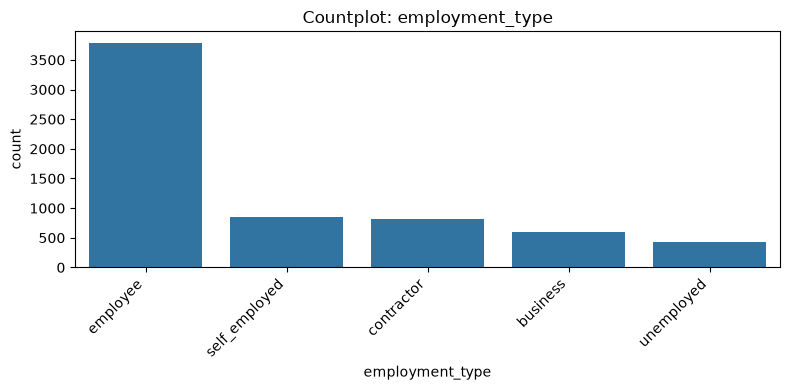

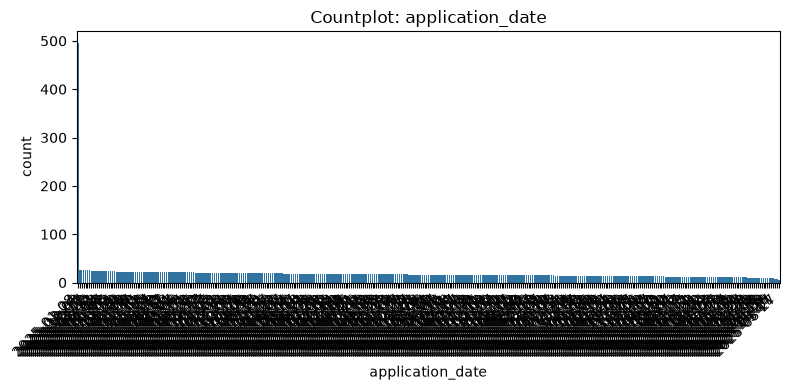

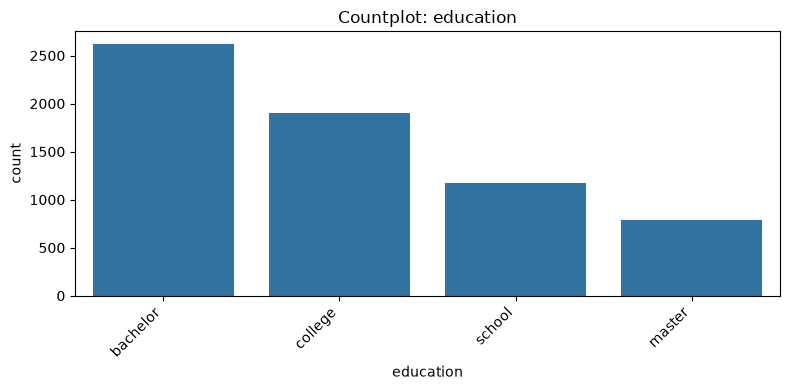

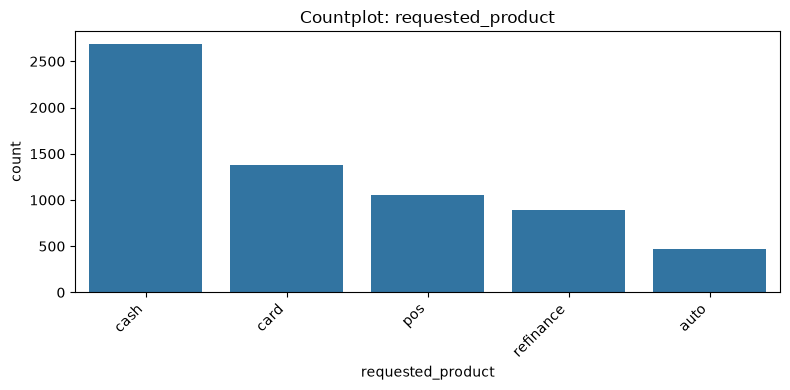

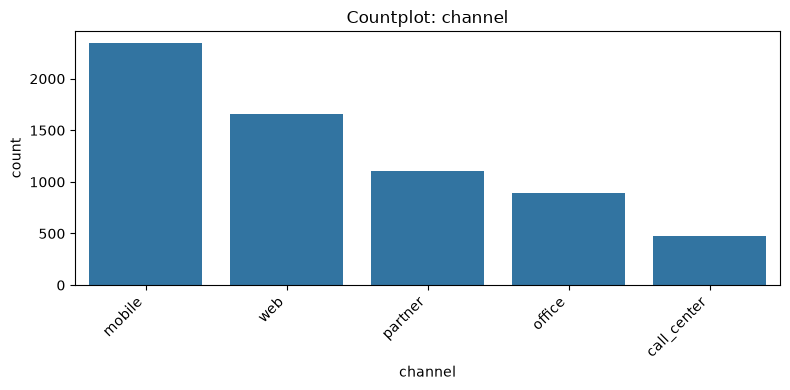

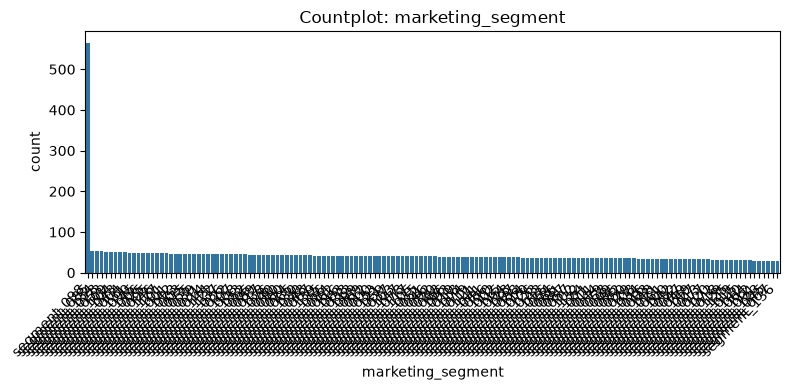

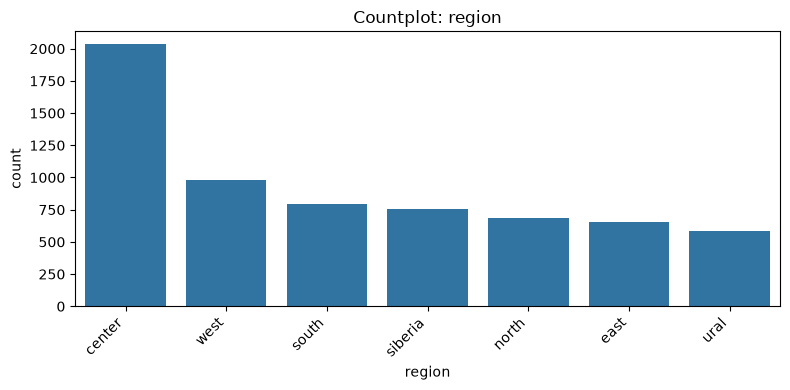

In [78]:
for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_train,x=col,order=df_train[col].value_counts().index)

    plt.title(f'Countplot: {col}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Для marketing_segment применим Frequency Encoding

### Применим One-hot encoding

In [79]:
cat_cols_encoding = ['employment_type','education','requested_product','channel','region']

df_train_encoding = pd.get_dummies(df_train, columns=cat_cols_encoding, dtype=int)
df_test_encoding = pd.get_dummies(df_test, columns=cat_cols_encoding, dtype=int)

freq = df_train["marketing_segment"].value_counts(normalize=True) #Frequency Encoding

df_train_encoding["marketing_segment"] = df_train["marketing_segment"].map(freq)
df_test_encoding["marketing_segment"] = df_test["marketing_segment"].map(freq).fillna(0)

In [80]:
df_train_encoding

,application_id,client_id,hash_id,region_coefficient_extended,age,incoming_amount,monthly_income,application_date,loan_amount,marketing_segment,region_coefficient,interest_rate,months_at_job,dependents,loan_term_months,siberia_northern_score,target,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,107941,7941,61441390.0,1.0,37.0,30401.28,30401.28,2025-08-11,63464.49,0.005401,1.0,0.3062,31.0,0.0,24.0,0.336102,1,3.0,72210.10,24070.033333,148917.360,49639.120000,15.0,5.000000,1594.0,1110.0,1.0,2.0,1.0,1.0,1.0,0.0,0.0,1.0,20623.70,20623.7000,36.0,62.0,62.0,0.0,0.0,0.0,0.0,35.0,-66394.980,-1896.999429,9444.87,-6075.02,2.171429,5.0,14936.68,-81331.660,7.0,3.0,1.0,11.0,4.0,2.0,3.0,4.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
1,101163,1163,67321556.0,0.0,60.0,26024.64,26024.64,2025-12-29,113513.59,0.006481,1.0,0.1383,90.0,0.0,6.0,0.560893,1,5.0,269069.01,53813.802000,702481.490,140496.298000,60.0,12.400000,2184.0,821.0,5.0,0.0,0.0,0.0,4.0,0.0,1.0,1.0,20284.16,20284.1600,24.0,1235.0,1235.0,0.0,0.0,0.0,0.0,29.0,-38064.910,-1312.583103,18781.61,-9106.18,2.275862,5.0,27247.35,-65312.260,8.0,3.0,0.0,9.0,2.0,2.0,3.0,2.0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,100583,583,26719968.0,0.0,37.0,21389.83,21389.83,2025-11-09,48993.42,0.087191,1.0,0.1729,57.0,1.0,9.0,0.509329,0,1.0,9362.87,9362.870000,101951.690,101951.690000,7.0,7.000000,329.0,329.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,102193.73,51096.8650,6.0,1565.0,873.0,7.0,3.5,1.0,1.0,26.0,-36777.170,-1414.506538,-187.66,-6653.02,2.230769,5.0,0.00,-36777.170,6.0,3.0,0.0,10.0,2.0,0.0,2.0,3.0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1
3,104082,4082,45184358.0,0.0,44.0,31617.26,37717.51,2025-02-23,77765.78,0.006636,1.0,0.3585,19.0,0.0,36.0,0.509329,0,1.0,59731.91,59731.910000,84660.990,84660.990000,0.0,0.000000,2320.0,2320.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,141115.00,141115.0000,24.0,769.0,769.0,0.0,0.0,0.0,0.0,34.0,58973.660,1734.519412,54653.96,-5104.79,2.117647,5.0,108932.62,-49958.960,2.0,3.0,0.0,10.0,3.0,6.0,7.0,3.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
4,108413,8413,58267524.0,0.0,60.0,18000.00,18000.00,2025-12-07,97254.10,0.006327,1.0,0.1472,405.0,0.0,9.0,0.741053,0,2.0,67273.84,27294.840000,165030.645,65932.865000,7.0,3.750000,2238.0,829.0,2.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,37376.14,37376.1400,24.0,1059.0,1059.0,0.0,0.0,0.0,0.0,33.0,-33647.990,-1019.636061,3257.70,-6482.34,2.121212,5.0,3257.70,-36905.690,9.0,3.0,1.0,8.0,4.0,1.0,6.0,1.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

In [81]:
df_test_encoding

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,months_at_job,monthly_income,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,application_date,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,102531,2531,0.0,18.0,0.509329,55020645.5,73071.51,38.0,34183.79,34183.79,44.0,0.0,0.2146,0.004475,1.0,2025-04-25,6.0,283471.660,47245.276667,730777.300,121796.216667,90.0,16.333333,2878.0,435.0,4.0,2.0,1.0,1.0,3.0,1.0,0.0,1.0,51373.33,51373.3300,18.0,1202.0,1202.0,0.0,0.0,0.0,0.0,25.0,-2231.640,-89.265600,31596.13,-6097.08,2.460000,5.0,42322.66,-44554.300,0.0,5.0,1.0,9.0,1.0,3.0,4.0,2.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,23.0,18645.00,18645.00,64.0,0.0,0.2851,0.007253,1.0,2025-05-07,3.0,105300.405,35100.135000,176139.640,58713.213333,7.0,5.000000,2172.0,497.0,2.0,1.0,0.0,0.0,2.0,0.0,1.0,2.0,151274.58,75637.2900,16.5,911.0,753.0,0.0,0.0,0.0,0.0,38.0,-10598.600,-278.910526,9944.85,-3697.95,2.157895,5.0,30691.14,-41289.740,5.0,6.0,1.0,10.0,4.0,4.0,5.0,3.0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0
2,100238,238,0.0,36.0,0.902039,92419982.0,67331.28,12.0,52931.84,52931.84,21.0,1.0,0.3810,0.006019,1.0,2025-02-26,1.0,25465.910,25465.910000,71929.370,71929.370000,7.0,7.000000,291.0,291.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,60434.71,60434.7100,18.0,422.0,422.0,0.0,0.0,0.0,0.0,45.0,-29585.490,-657.455333,33785.45,-24333.59,2.133333,5.0,125444.91,-155030.400,6.0,7.0,1.0,10.0,1.0,7.0,5.0,8.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,104918,4918,0.0,6.0,0.737848,76137566.0,67331.28,179.0,37717.51,37301.16,55.0,0.0,0.1471,0.005556,1.0,2025-12-07,3.0,38604.760,12868.253333,42168.375,14056.125000,30.0,10.000000,1982.0,850.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,39366.47,39366.4700,9.0,823.0,823.0,0.0,0.0,0.0,0.0,32.0,-52640.780,-1645.024375,10817.56,-6636.68,2.375000,5.0,15592.27,-68233.050,6.0,1.0,1.0,11.0,3.0,2.0,2.0,6.0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,153.0,71928.29,71928.29,55.0,1.0,0.1840,0.006636,1.0,2025-05-09,2.0,117046.450,58523.225000,198814.870,99407.435000,60.0,30.000000,2626.0,522.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,3.0,148311.27,49437.0900,5.0,1111.0,40.0,0.0,0.0,0.0,0.0,50.0,9937.100,198.742000,94078.05,-23963.42,2.140000,5.0,219174.13,-209237.030,10.0,4.0,1.0,15.0,6.0,5.0,7.0,2.0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...

In [ ]:
# df_train_encoding.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_train_encoding_2.csv', index=False)
# df_test_encoding.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_test_encoding_2.csv', index=False)

# Удалим выбросы
Раздел создан с целью демонстрации удаления выбросов. Применяться в общем pipeline не будет. Это связано с тем, что выбросы в финансовом секторе не всегда являются выбросами. Иногда человек действительно может взять бОльший кредит, чем обычно

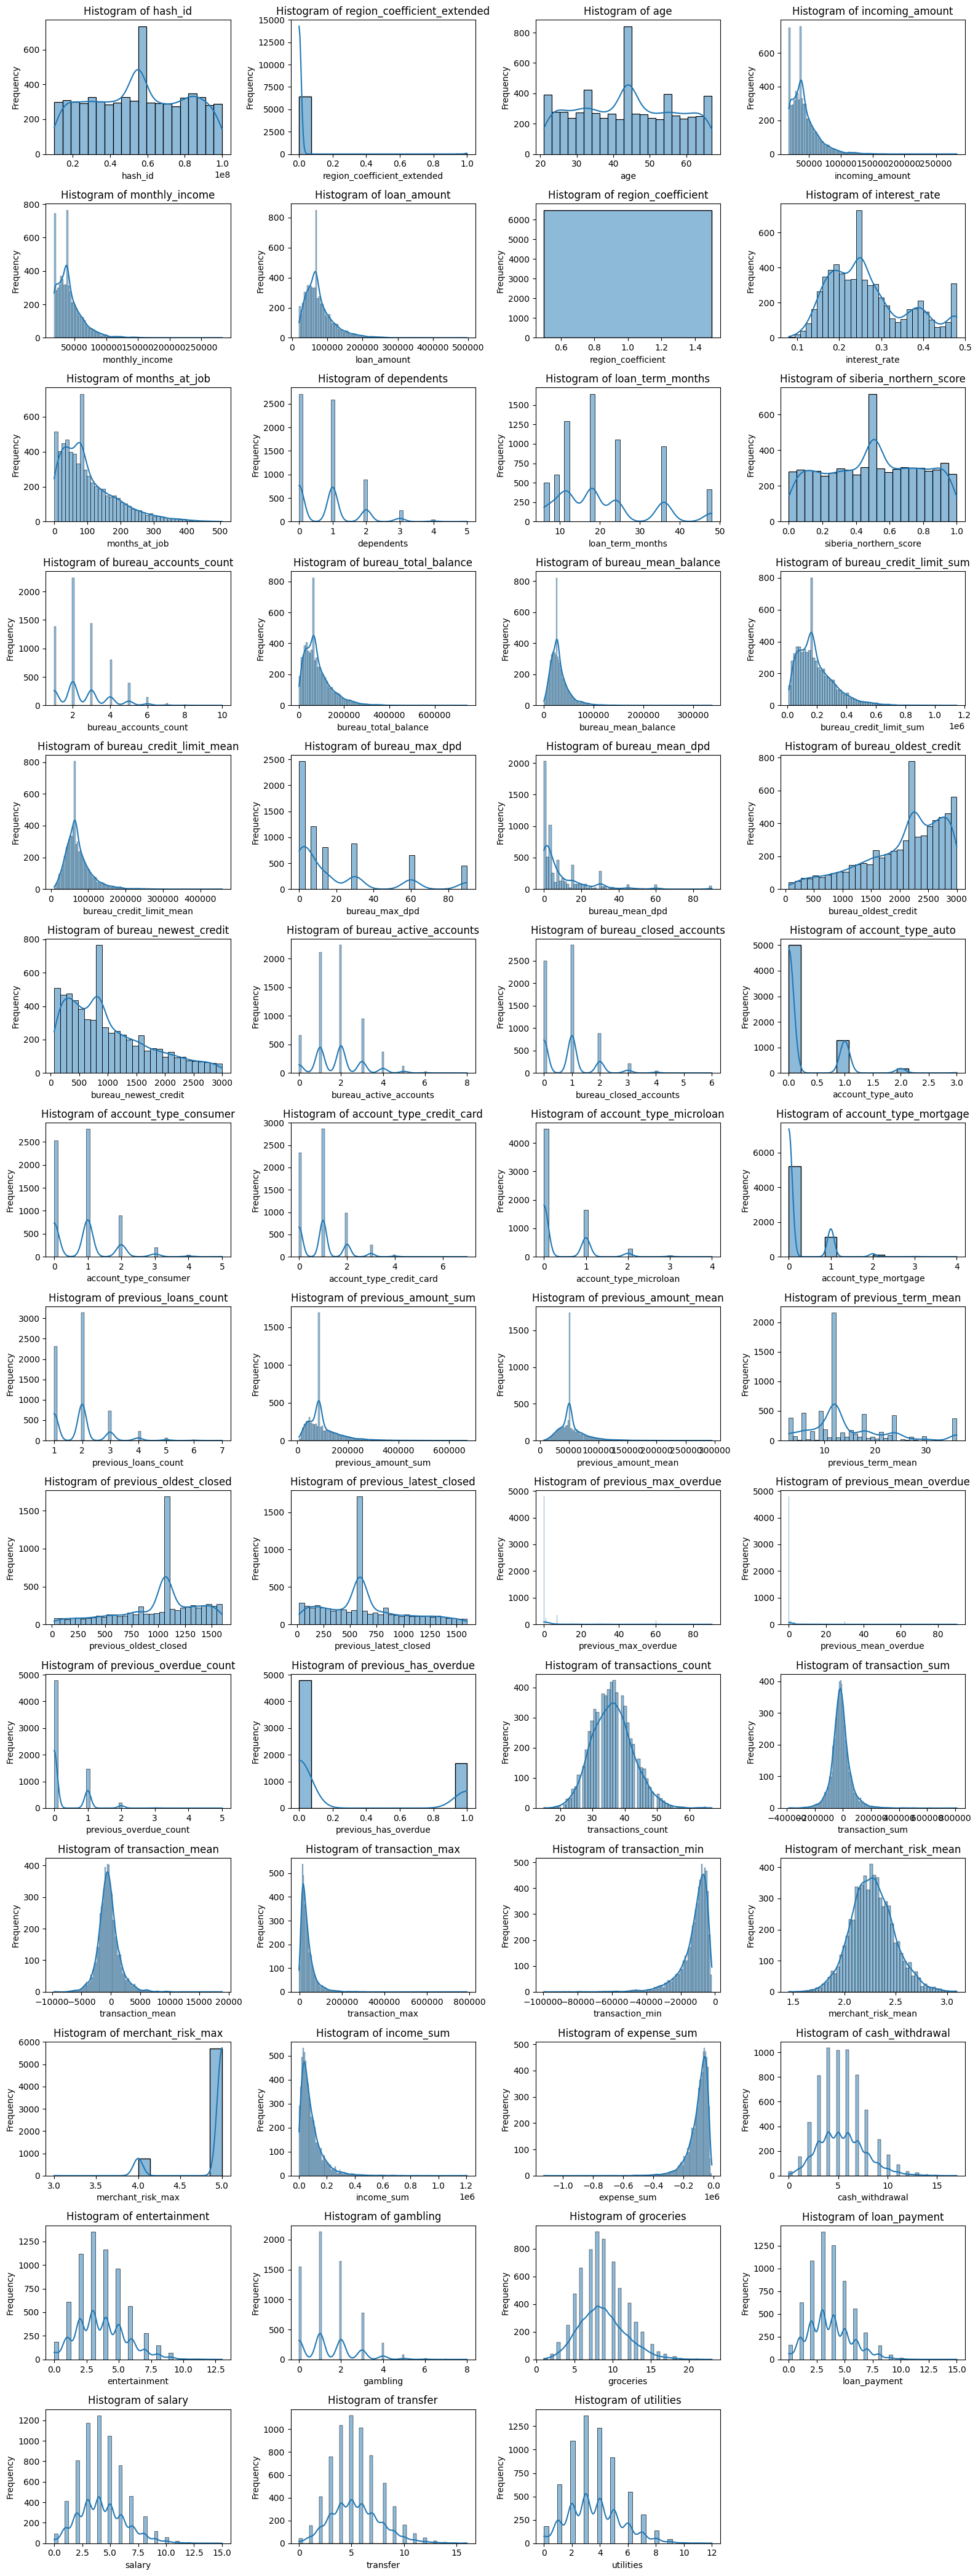

In [ ]:
# import math

# n_plots = len(num_cols)
# # Размер сетки графиков
# ncols = 4
# nrows = math.ceil(n_plots/ncols)

# # Размер каждого графика
# plt.figure(figsize=(4 * ncols, 3 * nrows))

# for i, col in enumerate(num_cols):
#     plt.subplot(nrows, ncols, i + 1)
#     sns.histplot(df_train[col], kde=True)
#     plt.title(f'Histogram of {col}')
#     plt.xlabel(col)
#     plt.ylabel('Frequency')

# plt.tight_layout()
# plt.show()

In [ ]:
# num_cols

Index(['hash_id', 'region_coefficient_extended', 'age', 'incoming_amount',
       'monthly_income', 'loan_amount', 'region_coefficient', 'interest_rate',
       'months_at_job', 'dependents', 'loan_term_months',
       'siberia_northern_score', 'bureau_accounts_count',
       'bureau_total_balance', 'bureau_mean_balance',
       'bureau_credit_limit_sum', 'bureau_credit_limit_mean', 'bureau_max_dpd',
       'bureau_mean_dpd', 'bureau_oldest_credit', 'bureau_newest_credit',
       'bureau_active_accounts', 'bureau_closed_accounts', 'account_type_auto',
       'account_type_consumer', 'account_type_credit_card',
       'account_type_microloan', 'account_type_mortgage',
       'previous_loans_count', 'previous_amount_sum', 'previous_amount_mean',
       'previous_term_mean', 'previous_oldest_closed',
       'previous_latest_closed', 'previous_max_overdue',
       'previous_mean_overdue', 'previous_overdue_count',
       'previous_has_overdue', 'transactions_count', 'transaction_sum',
    

In [ ]:
# incoming_amount monthly_income loan_amount bureau_total_balance bureau_mean_balance bureau_credit_limit_sum
# bureau_credit_limit_mean bureau_mean_dpd previous_amount_sum previous_amount_mean transaction_mean transaction_sum
# transaction_min transaction_max income_sum expense_sum

SyntaxError: invalid syntax (2010774248.py, line 1)

In [ ]:
# df_train.shape

(6480, 65)

In [ ]:
# columns_for_outlier_removal = [
#     'incoming_amount', 'monthly_income', 'loan_amount',
#     'bureau_total_balance', 'bureau_mean_balance', 'bureau_credit_limit_sum',
#     'bureau_credit_limit_mean', 'bureau_mean_dpd', 'previous_amount_sum',
#     'previous_amount_mean', 'transaction_mean', 'transaction_sum',
#     'transaction_min', 'transaction_max', 'income_sum', 'expense_sum'
# ]

# k_factor = 1.5 # Можно корректировать это значение для изменения порога удаления выбросов

# df_train_cleaned = df_train.copy()
# for col in columns_for_outlier_removal:
#     if col in df_train_cleaned.columns:
#         Q1 = df_train_cleaned[col].quantile(0.25)
#         Q3 = df_train_cleaned[col].quantile(0.75)
#         IQR = Q3 - Q1
#         lower_bound = Q1 - k_factor * IQR
#         upper_bound = Q3 + k_factor * IQR

#         # Filter out outliers
#         initial_shape = df_train_cleaned.shape[0]
#         df_train_cleaned = df_train_cleaned[(df_train_cleaned[col] >= lower_bound) & (df_train_cleaned[col] <= upper_bound)]
#         removed_rows = initial_shape - df_train_cleaned.shape[0]
#         print(f"Outliers removed for column: {col}. Removed {removed_rows} rows. New shape: {df_train_cleaned.shape}")

# print("\nDataFrame after outlier removal:")
# display(df_train_cleaned.shape)


Outliers removed for column: incoming_amount. Removed 280 rows. New shape: (6200, 65)
Outliers removed for column: monthly_income. Removed 82 rows. New shape: (6118, 65)
Outliers removed for column: loan_amount. Removed 309 rows. New shape: (5809, 65)
Outliers removed for column: bureau_total_balance. Removed 247 rows. New shape: (5562, 65)
Outliers removed for column: bureau_mean_balance. Removed 263 rows. New shape: (5299, 65)
Outliers removed for column: bureau_credit_limit_sum. Removed 96 rows. New shape: (5203, 65)
Outliers removed for column: bureau_credit_limit_mean. Removed 164 rows. New shape: (5039, 65)
Outliers removed for column: bureau_mean_dpd. Removed 307 rows. New shape: (4732, 65)
Outliers removed for column: previous_amount_sum. Removed 325 rows. New shape: (4407, 65)
Outliers removed for column: previous_amount_mean. Removed 372 rows. New shape: (4035, 65)
Outliers removed for column: transaction_mean. Removed 175 rows. New shape: (3860, 65)
Outliers removed for colu

(3313, 65)

# Обучение моделей классификации


In [ ]:
# df_train_encoding = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_train_encoding_2.csv')
# df_train_encoding

,application_id,client_id,hash_id,region_coefficient_extended,age,incoming_amount,monthly_income,application_date,loan_amount,marketing_segment,region_coefficient,interest_rate,months_at_job,dependents,loan_term_months,siberia_northern_score,target,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,107941,7941,61441390.0,1.0,37.0,30401.28,30401.28,2025-08-11,63464.49,0.005401,1.0,0.3062,31.0,0.0,24.0,0.336102,1,3.0,72210.10,24070.033333,148917.360,49639.120000,15.0,5.000000,1594.0,1110.0,1.0,2.0,1.0,1.0,1.0,0.0,0.0,1.0,20623.70,20623.7000,36.0,62.0,62.0,0.0,0.0,0.0,0.0,35.0,-66394.980,-1896.999429,9444.87,-6075.02,2.171429,5.0,14936.68,-81331.660,7.0,3.0,1.0,11.0,4.0,2.0,3.0,4.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
1,101163,1163,67321556.0,0.0,60.0,26024.64,26024.64,2025-12-29,113513.59,0.006481,1.0,0.1383,90.0,0.0,6.0,0.560893,1,5.0,269069.01,53813.802000,702481.490,140496.298000,60.0,12.400000,2184.0,821.0,5.0,0.0,0.0,0.0,4.0,0.0,1.0,1.0,20284.16,20284.1600,24.0,1235.0,1235.0,0.0,0.0,0.0,0.0,29.0,-38064.910,-1312.583103,18781.61,-9106.18,2.275862,5.0,27247.35,-65312.260,8.0,3.0,0.0,9.0,2.0,2.0,3.0,2.0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,100583,583,26719968.0,0.0,37.0,21389.83,21389.83,2025-11-09,48993.42,0.087191,1.0,0.1729,57.0,1.0,9.0,0.509329,0,1.0,9362.87,9362.870000,101951.690,101951.690000,7.0,7.000000,329.0,329.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,102193.73,51096.8650,6.0,1565.0,873.0,7.0,3.5,1.0,1.0,26.0,-36777.170,-1414.506538,-187.66,-6653.02,2.230769,5.0,0.00,-36777.170,6.0,3.0,0.0,10.0,2.0,0.0,2.0,3.0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1
3,104082,4082,45184358.0,0.0,44.0,31617.26,37717.51,2025-02-23,77765.78,0.006636,1.0,0.3585,19.0,0.0,36.0,0.509329,0,1.0,59731.91,59731.910000,84660.990,84660.990000,0.0,0.000000,2320.0,2320.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,141115.00,141115.0000,24.0,769.0,769.0,0.0,0.0,0.0,0.0,34.0,58973.660,1734.519412,54653.96,-5104.79,2.117647,5.0,108932.62,-49958.960,2.0,3.0,0.0,10.0,3.0,6.0,7.0,3.0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
4,108413,8413,58267524.0,0.0,60.0,18000.00,18000.00,2025-12-07,97254.10,0.006327,1.0,0.1472,405.0,0.0,9.0,0.741053,0,2.0,67273.84,27294.840000,165030.645,65932.865000,7.0,3.750000,2238.0,829.0,2.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,37376.14,37376.1400,24.0,1059.0,1059.0,0.0,0.0,0.0,0.0,33.0,-33647.990,-1019.636061,3257.70,-6482.34,2.121212,5.0,3257.70,-36905.690,9.0,3.0,1.0,8.0,4.0,1.0,6.0,1.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,

In [ ]:
# df_test_encoding = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/df_test_encoding_2.csv')
# df_test_encoding

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,months_at_job,monthly_income,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,application_date,bureau_accounts_count,bureau_total_balance,bureau_mean_balance,bureau_credit_limit_sum,bureau_credit_limit_mean,bureau_max_dpd,bureau_mean_dpd,bureau_oldest_credit,bureau_newest_credit,bureau_active_accounts,bureau_closed_accounts,account_type_auto,account_type_consumer,account_type_credit_card,account_type_microloan,account_type_mortgage,previous_loans_count,previous_amount_sum,previous_amount_mean,previous_term_mean,previous_oldest_closed,previous_latest_closed,previous_max_overdue,previous_mean_overdue,previous_overdue_count,previous_has_overdue,transactions_count,transaction_sum,transaction_mean,transaction_max,transaction_min,merchant_risk_mean,merchant_risk_max,income_sum,expense_sum,cash_withdrawal,entertainment,gambling,groceries,loan_payment,salary,transfer,utilities,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,education_bachelor,education_college,education_master,education_school,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance,channel_call_center,channel_mobile,channel_office,channel_partner,channel_web,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west
0,102531,2531,0.0,18.0,0.509329,55020645.5,73071.51,38.0,34183.79,34183.79,44.0,0.0,0.2146,0.004475,1.0,2025-04-25,6.0,283471.660,47245.276667,730777.300,121796.216667,90.0,16.333333,2878.0,435.0,4.0,2.0,1.0,1.0,3.0,1.0,0.0,1.0,51373.33,51373.3300,18.0,1202.0,1202.0,0.0,0.0,0.0,0.0,25.0,-2231.640,-89.265600,31596.13,-6097.08,2.460000,5.0,42322.66,-44554.300,0.0,5.0,1.0,9.0,1.0,3.0,4.0,2.0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,23.0,18645.00,18645.00,64.0,0.0,0.2851,0.007253,1.0,2025-05-07,3.0,105300.405,35100.135000,176139.640,58713.213333,7.0,5.000000,2172.0,497.0,2.0,1.0,0.0,0.0,2.0,0.0,1.0,2.0,151274.58,75637.2900,16.5,911.0,753.0,0.0,0.0,0.0,0.0,38.0,-10598.600,-278.910526,9944.85,-3697.95,2.157895,5.0,30691.14,-41289.740,5.0,6.0,1.0,10.0,4.0,4.0,5.0,3.0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0
2,100238,238,0.0,36.0,0.902039,92419982.0,67331.28,12.0,52931.84,52931.84,21.0,1.0,0.3810,0.006019,1.0,2025-02-26,1.0,25465.910,25465.910000,71929.370,71929.370000,7.0,7.000000,291.0,291.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,60434.71,60434.7100,18.0,422.0,422.0,0.0,0.0,0.0,0.0,45.0,-29585.490,-657.455333,33785.45,-24333.59,2.133333,5.0,125444.91,-155030.400,6.0,7.0,1.0,10.0,1.0,7.0,5.0,8.0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
3,104918,4918,0.0,6.0,0.737848,76137566.0,67331.28,179.0,37717.51,37301.16,55.0,0.0,0.1471,0.005556,1.0,2025-12-07,3.0,38604.760,12868.253333,42168.375,14056.125000,30.0,10.000000,1982.0,850.0,2.0,1.0,0.0,2.0,1.0,0.0,0.0,1.0,39366.47,39366.4700,9.0,823.0,823.0,0.0,0.0,0.0,0.0,32.0,-52640.780,-1645.024375,10817.56,-6636.68,2.375000,5.0,15592.27,-68233.050,6.0,1.0,1.0,11.0,3.0,2.0,2.0,6.0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,153.0,71928.29,71928.29,55.0,1.0,0.1840,0.006636,1.0,2025-05-09,2.0,117046.450,58523.225000,198814.870,99407.435000,60.0,30.000000,2626.0,522.0,2.0,0.0,0.0,1.0,1.0,0.0,0.0,3.0,148311.27,49437.0900,5.0,1111.0,40.0,0.0,0.0,0.0,0.0,50.0,9937.100,198.742000,94078.05,-23963.42,2.140000,5.0,219174.13,-209237.030,10.0,4.0,1.0,15.0,6.0,5.0,7.0,2.0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...

In [82]:
df_train_encoding['target'].value_counts(normalize=True)

target
0    0.657716
1    0.342284
Name: proportion, dtype: float64

In [83]:
df_train_encoding['application_date'] = pd.to_datetime(df_train_encoding['application_date'])
df_test_encoding['application_date'] = pd.to_datetime(df_test_encoding['application_date'])

In [84]:
df_train_encoding.info()

<class 'pandas.DataFrame'>
RangeIndex: 6480 entries, 0 to 6479
Data columns (total 86 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   application_id                 6480 non-null   int64         
 1   client_id                      6480 non-null   int64         
 2   hash_id                        6480 non-null   float64       
 3   region_coefficient_extended    6480 non-null   float64       
 4   age                            6480 non-null   float64       
 5   incoming_amount                6480 non-null   float64       
 6   monthly_income                 6480 non-null   float64       
 7   application_date               6480 non-null   datetime64[us]
 8   loan_amount                    6480 non-null   float64       
 9   marketing_segment              6480 non-null   float64       
 10  region_coefficient             6480 non-null   float64       
 11  interest_rate               

### Удалим столбцы с ID, application_date и target перед корреляционной матрицей и стандартизацией

In [85]:
df_target = df_train_encoding['target']
df_application_id = df_test_encoding['application_id']

In [86]:
df_train_encoding = df_train_encoding.drop(columns=['application_id','client_id','application_date','target'])
df_test_encoding = df_test_encoding.drop(columns=['application_id','client_id','application_date'])

### Correlation_matrix

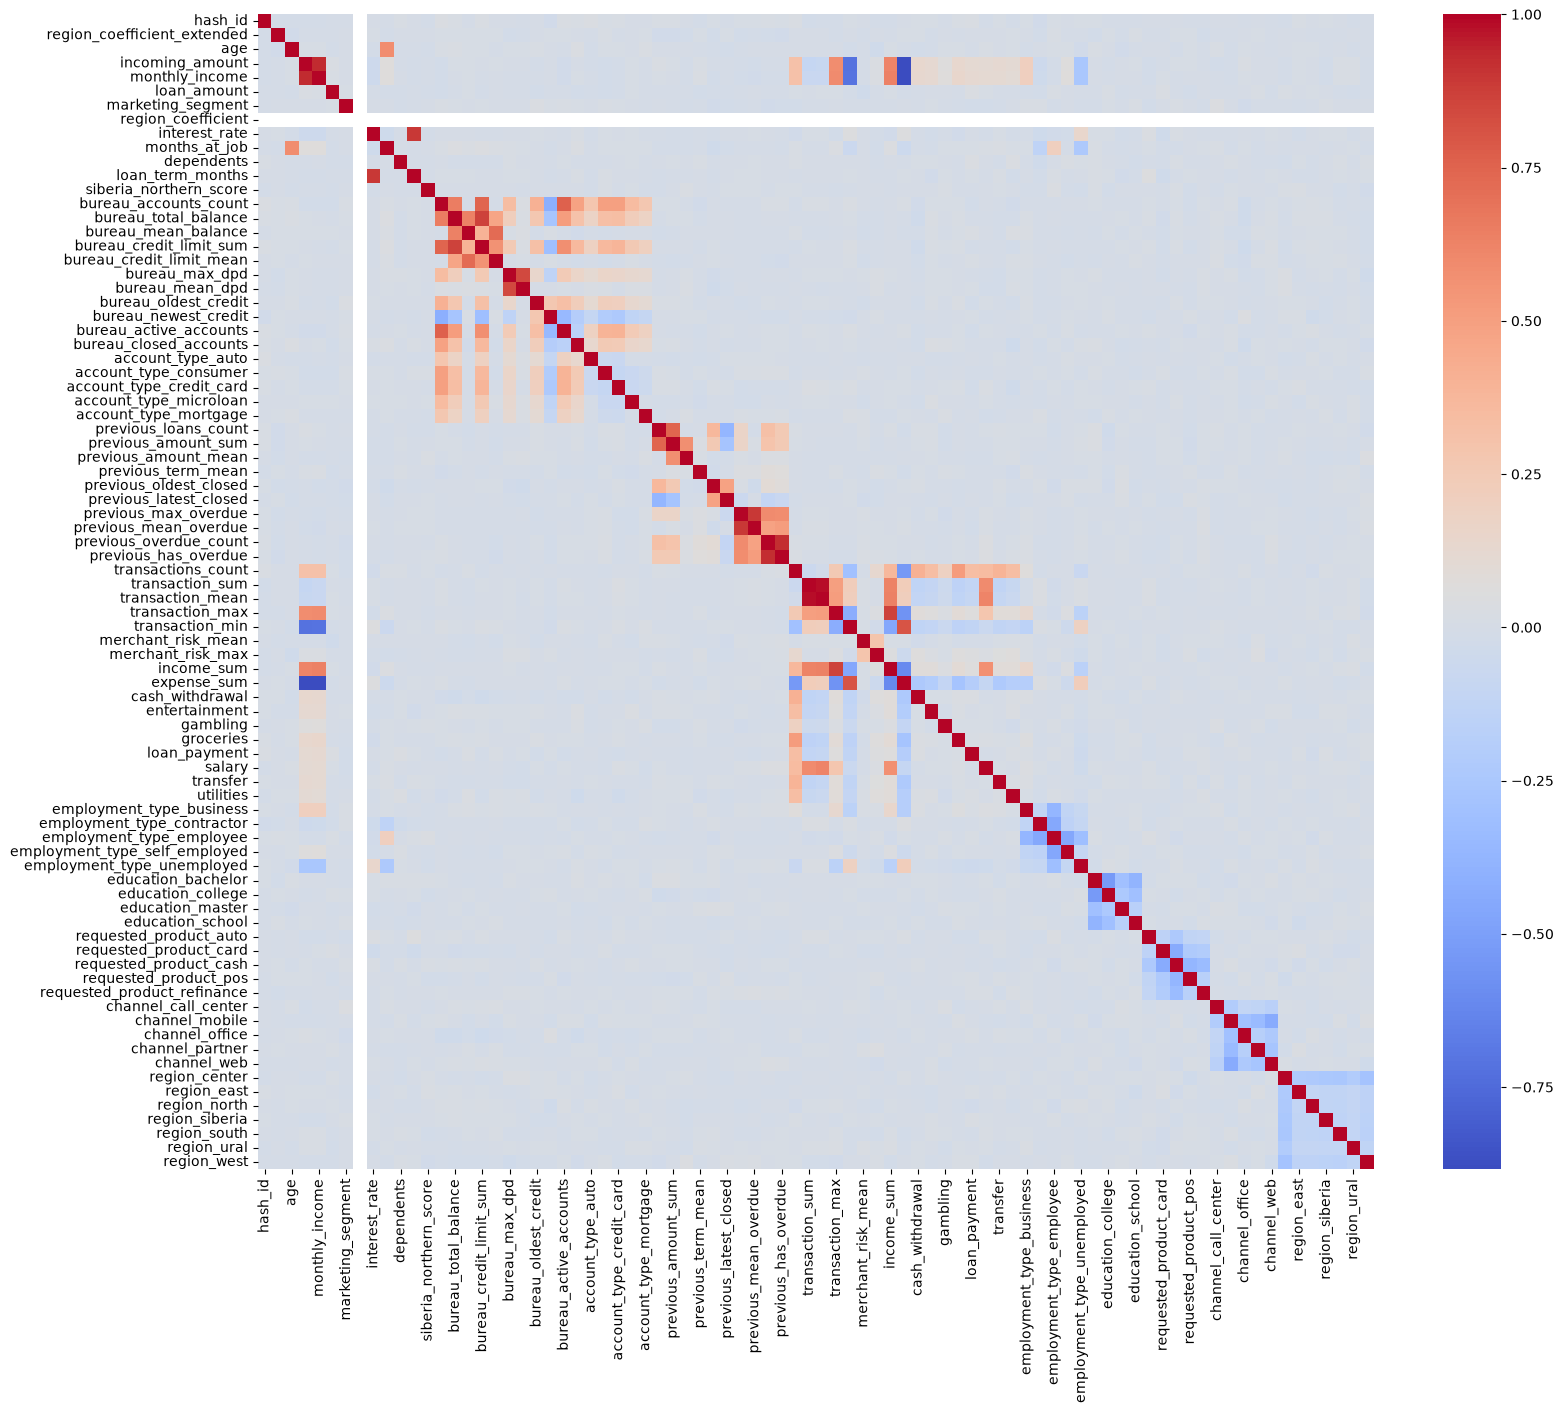

In [87]:
plt.figure(figsize=(18, 15))
sns.heatmap(df_train_encoding.corr(), cmap="coolwarm")
plt.show()

In [88]:
corr_matrix = df_train_encoding.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.80)]
print(to_drop)

['monthly_income', 'loan_term_months', 'bureau_credit_limit_sum', 'bureau_mean_dpd', 'previous_mean_overdue', 'previous_has_overdue', 'transaction_mean', 'income_sum', 'expense_sum']


In [89]:
df_train_encoding.drop(columns=to_drop, inplace=True)
df_test_encoding.drop(columns=to_drop, inplace=True)

In [90]:
df_train_encoding = pd.concat([df_train_encoding, df_target], axis=1)

In [91]:
df_train_encoding.columns

Index(['hash_id', 'region_coefficient_extended', 'age', 'incoming_amount',
       'loan_amount', 'marketing_segment', 'region_coefficient',
       'interest_rate', 'months_at_job', 'dependents',
       'siberia_northern_score', 'bureau_accounts_count',
       'bureau_total_balance', 'bureau_mean_balance',
       'bureau_credit_limit_mean', 'bureau_max_dpd', 'bureau_oldest_credit',
       'bureau_newest_credit', 'bureau_active_accounts',
       'bureau_closed_accounts', 'account_type_auto', 'account_type_consumer',
       'account_type_credit_card', 'account_type_microloan',
       'account_type_mortgage', 'previous_loans_count', 'previous_amount_sum',
       'previous_amount_mean', 'previous_term_mean', 'previous_oldest_closed',
       'previous_latest_closed', 'previous_max_overdue',
       'previous_overdue_count', 'transactions_count', 'transaction_sum',
       'transaction_max', 'transaction_min', 'merchant_risk_mean',
       'merchant_risk_max', 'cash_withdrawal', 'entertainment',

### Разделим данные на признаки в X и y с таргетной величиной

In [92]:
X = df_train_encoding.drop(columns=['target'])
y = df_train_encoding['target']
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X = X_scaled

df_test_encoding_aligned = df_test_encoding[X.columns]
X_test_scaled = pd.DataFrame(scaler.transform(df_test_encoding_aligned), columns=df_test_encoding_aligned.columns, index=df_test_encoding_aligned.index)
df_test_encoding_scaled = X_test_scaled

### Применим Cross-validation для сбалансированного обучения и упрощения оценки ROC AUC на нескольких фолдах

In [93]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [94]:
def evaluate_model(model, model_name):
    scores = []
    for fold, (train_idx, valid_idx) in enumerate(tqdm(cv.split(X, y),total=cv.n_splits,desc=f'{model_name} Cross-Validation')):
      X_train = X.iloc[train_idx]
      X_valid = X.iloc[valid_idx]
      y_train = y.iloc[train_idx]
      y_valid = y.iloc[valid_idx]
      model.fit(X_train, y_train)
      pred = model.predict_proba(X_valid)[:,1]
      score = roc_auc_score(y_valid, pred)
      scores.append(score)

    mean_score = np.mean(scores)
    print(f'Mean ROC-AUC for {model_name} = {mean_score:.5f}')
    return mean_score

In [95]:
cat_boost = CatBoostClassifier(iterations=2000,learning_rate=0.03,depth=6,l2_leaf_reg=5,loss_function='Logloss',eval_metric='AUC',random_seed=42,verbose=False)
log_reg = LogisticRegression(max_iter=2000,random_state=42)
xgb = XGBClassifier(n_estimators=1000,learning_rate=0.05,max_depth=6,subsample=0.8,colsample_bytree=0.8
                    ,eval_metric='logloss',random_state=42)
random_forest_clf = RandomForestClassifier(n_estimators=300,random_state=42,n_jobs=-1)
lg = LGBMClassifier(n_estimators=1000,learning_rate=0.05,max_depth=6,subsample=0.8,colsample_bytree=0.8
                    ,random_state=42, verbose=-1)

In [ ]:
models = {
    "LogisticRegression": log_reg,
    "RandomForest": random_forest_clf,
    "XGBoost": xgb,
    "CatBoost": cat_boost,
    "LightGBM": lg
}

results = {}
for model_name, model in models.items():
    results[model_name] = evaluate_model(model, model_name)

LogisticRegression Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for LogisticRegression = 0.81459


RandomForest Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for RandomForest = 0.80276


XGBoost Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for XGBoost = 0.80169


CatBoost Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for CatBoost = 0.80780


LightGBM Cross-Validation:   0%|          | 0/5 [00:00<?, ?it/s]

Mean ROC-AUC for LightGBM = 0.79064


Лучший результат показала LogisticRegression. Попробуем провести настройку гиперпараметров, применим Optuna

### Настройка гиперпараметров с Optuna

In [ ]:
def objective(trial):

    model = LogisticRegression(
        C=trial.suggest_float("C", 1e-5, 100, log=True),
        max_iter=2000,
        random_state=42
    )

    return evaluate_model(model, "LogisticRegression")

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

In [ ]:
print(study.best_params)
print(study.best_value)

{'C': 3.770453687147913}
0.8146041555443766


In [ ]:
def objective_rf(trial):

    model = RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        max_depth=trial.suggest_int("max_depth", 3, 20),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        random_state=42,
        n_jobs=-1
    )

    return evaluate_model(model, "RandomForest")

In [ ]:
study_rf = optuna.create_study(direction="maximize")
study_rf.optimize(objective_rf, n_trials=30)

In [ ]:
print(study_rf.best_params)
print(study_rf.best_value)

{'n_estimators': 346, 'max_depth': 14, 'min_samples_split': 8, 'min_samples_leaf': 7}
0.8066214642310807


In [ ]:
def objective_xgb(trial):

    model = XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        eval_metric="logloss",
        random_state=42
    )

    return evaluate_model(model, "XGBoost")

In [ ]:
study_xgb = optuna.create_study(direction="maximize")
study_xgb.optimize(objective_xgb, n_trials=30)

In [ ]:
print(study_xgb.best_params)
print(study_xgb.best_value)

{'n_estimators': 334, 'learning_rate': 0.03709014370668261, 'max_depth': 3, 'subsample': 0.6129591894424666, 'colsample_bytree': 0.5974041222843645}
0.8183694126214004


In [ ]:
def objective_cat(trial):

    model = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 300, 2000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        depth=trial.suggest_int("depth", 4, 10),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1, 10),
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=False
    )

    return evaluate_model(model, "CatBoost")

In [ ]:
study_cat = optuna.create_study(direction="maximize")
study_cat.optimize(objective_cat, n_trials=30)

In [ ]:
print(study_cat.best_params)
print(study_cat.best_value)

{'iterations': 731, 'learning_rate': 0.016690317231983942, 'depth': 4, 'l2_leaf_reg': 2.6109378008996846}
0.8214033360381338


In [ ]:
def objective_lgb(trial):

    model = LGBMClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 1000),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        random_state=42,
        verbose=-1
    )

    return evaluate_model(model, "LightGBM")

In [ ]:
study_lgb = optuna.create_study(direction="maximize")
study_lgb.optimize(objective_lgb, n_trials=30)

In [ ]:
print(study_lgb.best_params)
print(study_lgb.best_value)

{'n_estimators': 647, 'learning_rate': 0.014217508755960905, 'max_depth': 3, 'subsample': 0.6075835995222028, 'colsample_bytree': 0.8006140769259188}
0.8163182639115029


In [ ]:
optimized_models = {
    "LogisticRegression": LogisticRegression(C=3.770453687147913, max_iter=2000, random_state=42),

    "RandomForest": RandomForestClassifier(n_estimators=346, max_depth=14, min_samples_split=8, min_samples_leaf=7, random_state=42, n_jobs=-1),

    "XGBoost": XGBClassifier(n_estimators=334, learning_rate=0.03709014370668261, max_depth=3, subsample=0.6129591894424666, colsample_bytree=0.5974041222843645, eval_metric="logloss", random_state=42),

    "CatBoost": CatBoostClassifier(iterations=731, learning_rate=0.016690317231983942, depth=4, l2_leaf_reg=2.6109378008996846, loss_function="Logloss", eval_metric="AUC", random_seed=42, verbose=False),

    "LightGBM": LGBMClassifier(n_estimators=647, learning_rate=0.014217508755960905, max_depth=3, subsample=0.6075835995222028, colsample_bytree=0.8006140769259188, random_state=42, verbose=-1)
}

results = {}

for model_name, model in optimized_models.items():
    results[model_name] = evaluate_model(model, model_name)

In [ ]:
results = {
    "LogisticRegression": 0.81460,
    "RandomForest": 0.8066,
    "XGBoost": 0.8184,
    "CatBoost": 0.8214,
    "LightGBM": 0.8163
}

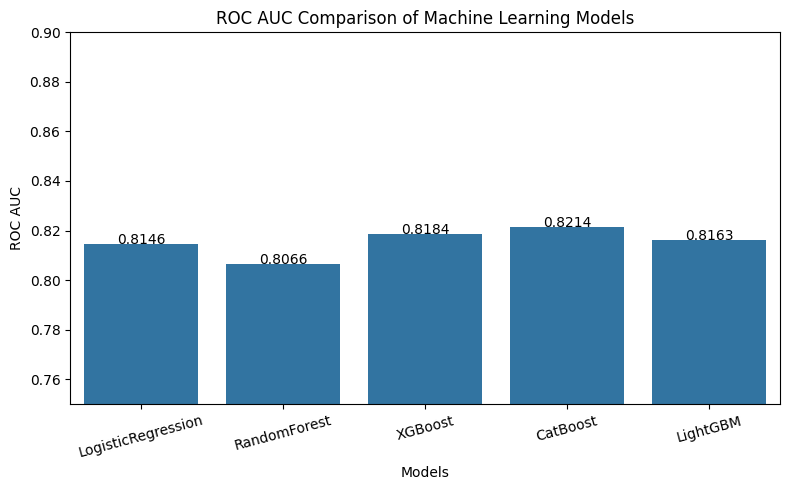

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()))

plt.title("ROC AUC Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("ROC AUC")
plt.ylim(0.75, 0.90)

for i, score in enumerate(results.values()):
    plt.text(i, score, f"{score:.4f}", ha="center")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### График обучения ROC AUC

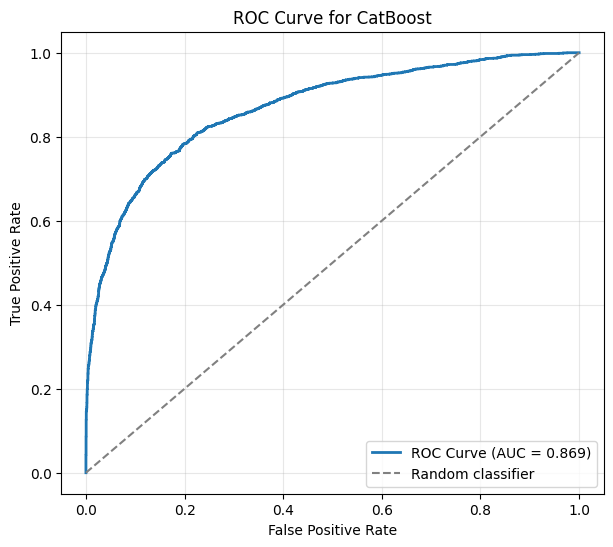

In [ ]:
from sklearn.metrics import roc_curve, auc

main_model = CatBoostClassifier(iterations=731, learning_rate=0.016690317231983942, depth=4, l2_leaf_reg=2.6109378008996846, loss_function="Logloss", eval_metric="AUC", random_seed=42, verbose=False)
main_model.fit(X, y)
pred = main_model.predict_proba(X)[:, 1]

fpr, tpr, thresholds = roc_curve(y, pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for CatBoost')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

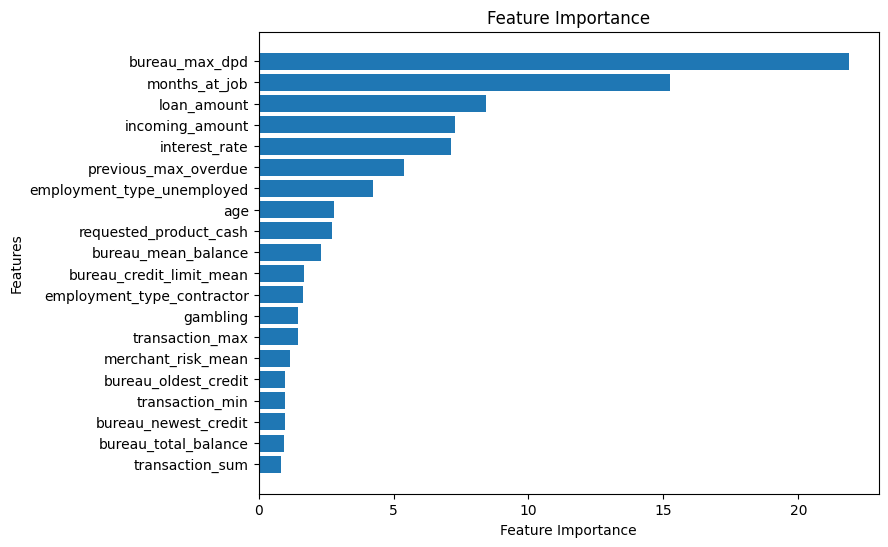

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": main_model.feature_importances_
})

importance = importance.sort_values("Importance", ascending=False).head(20)
importance = importance.sort_values("Importance")
plt.figure(figsize=(8, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Feature Importance")
plt.show()

Больше всего на модель влияет максимальное число дней просрочки платежей и сколько человек трудоустроено

### Финальное обучение

In [96]:
main_model = CatBoostClassifier(iterations=731, learning_rate=0.016690317231983942, depth=4, l2_leaf_reg=2.6109378008996846, loss_function="Logloss", eval_metric="AUC", random_seed=42, verbose=False)
main_model.fit(X,y)

CatBoostClassifier(depth=4, eval_metric='AUC', iterations=731, l2_leaf_reg=2.6109378008996846, learning_rate=0.016690317231983942, loss_function='Logloss', random_seed=42, verbose=False)

In [97]:
result_main_model = evaluate_model(main_model, "CatBoost")
print(result_main_model)

CatBoost Cross-Validation: 100%|██████████| 5/5 [00:32<00:00,  6.58s/it]

Mean ROC-AUC for CatBoost = 0.82169
0.8216905946767608


In [98]:
import joblib

joblib.dump(main_model, "Catboostmodel_credit_scoring.pkl")

['Catboostmodel_credit_scoring.pkl']

In [99]:
test_pred = main_model.predict_proba(df_test_encoding_scaled)[:,1]

In [100]:
submission = pd.DataFrame({"application_id": df_application_id,"target": test_pred})

submission

,application_id,target
0,102531,0.830924
1,107213,0.602297
2,100238,0.152071
3,104918,0.233817
4,106480,0.389174
...,...,...
2515,105735,0.338666
2516,105192,0.424631
2517,105391,0.259468
2518,100861,0.415227


In [ ]:
submission.to_csv('/content/drive/MyDrive/Shift_ML_07.2026/submission_2.csv', index=False)